<a href="https://colab.research.google.com/github/wcuelloj/S3_X-Clone/blob/main/V2_3_Texas_Battery_Price_Forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Texas battery: when to charge and when to discharge

**Goal.** Every morning, just before ERCOT's 10:00 day-ahead deadline, forecast tomorrow's 24 hourly electricity prices. Then tell the battery owner which hours to **charge** (cheapest) and which to **discharge** (most expensive, after charging).

**Data.** `texas_hourly_2021_2026.csv.gz`: one row per hour, 2021-01-01 to 2026-11, 146 columns. Every forecast column holds the version published before 10:00 the day before, so the model only uses what a real operator would have known.

**Plan of this notebook**
1. Settings (hub, battery size)
2. Load and check the data
3. Build inputs that are known before the deadline (no leakage)
4. Split by time: train 2021–2023, tune on 2024, test on 2025 and on the new market after 5 Dec 2025
5. Train models: baselines, Ridge, Random Forest, XGBoost, LightGBM, neural network, LightGBM price range (P10/P50/P90)
6. Score each model on price error **and on the money a battery earns following its plan**
7. Charts, what drives price, and a sample "tomorrow" recommendation

Runtime: about 15 minutes in total (tested on a laptop; the free Colab tier is similar). Training the models takes most of it.

## How this works, in one page

**The job.** Every morning, before ERCOT's 10:00 day-ahead deadline, you commit to tomorrow's battery schedule. You cannot change your mind afterwards, so everything depends on guessing tomorrow's 24 hourly prices.

**What the model may look at.** Only what a real operator would have at 09:30: ERCOT's published forecasts of demand, wind, solar and weather; gas prices; planned outages and spare capacity; and past prices - day-ahead at least 24 hours old, real-time at least 48, because that is when they were actually published. Anything measured on the day itself is excluded, since using it would be cheating.

**How the guess is made.** Gradient-boosted trees. A tree is a flowchart of yes/no questions - "is net load above 60 GW?", "is the reserve margin thin?" - ending in a price estimate. One tree is crude, so the model builds roughly 1,200 of them, each trained on what the previous ones got wrong, and adds them up. Prices are squashed with arcsinh first: Texas prices run from below zero to about 5,000 USD/MWh, and without squashing, a handful of spike hours would drown out the fifty thousand ordinary ones.

**Then the battery decides.** Given 24 predicted prices, a simple optimiser picks the cheapest hours to charge and later expensive hours to discharge. That plan is then paid at the **actual** prices, never the predicted ones. Value captured is what you earned divided by what a perfect forecast would have earned.

**The insight that explains the rest of this notebook.** The model does not need the price *level* right - it needs the *order* of the hours right. Being wrong by 5 USD/MWh on every hour costs nothing if the ranking holds. That is why the ranking-trained model wins, why `day_rank_corr` tracks profit more faithfully than R2 does, and why large accuracy gains repeatedly failed to turn into money.

### What trains, what tests

| Period | Hours | Role |
|---|---|---|
| 2021-01-08 to 2023-12-31 | 25,920 | train |
| 2024 | 8,784 | choose settings, fit blend weights, calibrate the band - **never scored** |
| 2025-01-01 to 2025-12-04 | 8,112 | test, old market rules |
| 2025-12-05 to 2026-10-31 | 7,943 | test, redesigned market (RTC+B) |

Never split at random: the test period is always the future. Winter Storm Uri week is removed from training. From January 2024 onward the model also retrains every month on everything before that month, so nothing ever sees its own future.

### How many models

Fourteen entries appear on the leaderboard - eleven learned, three benchmarks - and they are built from roughly 190 individual model fits:

| Stage | Fits |
|---|---|
| Settings search | 20 settings x 2 folds = 40, all discarded after choosing |
| Static models | 8, plus 3 price-range models |
| Monthly refits of the price model | 34 |
| Monthly refits of the ranker | 34 |
| Monthly refits of the spike classifier | ~34 |
| Quarterly refits of the price ranges | 12 x 3 = 36 |
| Deep-learning folds | 4 |
| Champion model for the SHAP analysis | 1 |

On top of those sit the blends, which are weighted averages of other models' outputs rather than fits of their own.

## 1. Settings

Change these to match the battery. `BATTERY_HOURS` is how many hours it takes to fully charge at full power: a 100 MW / 200 MWh battery has `BATTERY_HOURS = 2`.

The cells below download the dataset and set the battery parameters. If the Dropbox folder link fails, a fallback fetches the single data file directly.

In [ ]:
# Downloads the dataset; the fallback block at the bottom runs only if the
# folder link fails.
# Get the data from Dropbox (dl=1 downloads the folder as a zip)
!wget -q -O /content/tx.zip "https://www.dropbox.com/scl/fo/0gy0k4rxf7c8wh643o8ta/ANd1vYSBi74FMEm-VxndGA4?rlkey=bpspezq9nlo7az1totskzvc0c&dl=1"
!unzip -o -q /content/tx.zip -d /content/tx
DATA_PATH = '/content/tx/texas_hourly_2021_2026.csv.gz'

HUB = 'hb_hubavg'      # price location: hb_hubavg, hb_houston, hb_north, hb_south, hb_west
BATTERY_MW = 100       # power, MW
BATTERY_HOURS = 2      # storage duration, hours = hours charged and discharged per day
EFFICIENCY = 0.87      # round-trip efficiency (share of energy you get back)

TARGET = f'target_da_price_{HUB}'         # day-ahead price we forecast ($/MWh)
RT_COL = f'target_rt_price_{HUB}_mean'    # real-time price (only used with a 48 h delay)
SEED = 42
# Fallback: if the folder download above did not produce the file, fetch the
# single file directly instead.
import os, subprocess
if not os.path.exists(DATA_PATH):
    print('folder link did not produce the file - trying the direct link')
    os.makedirs('/content/tx', exist_ok=True)
    subprocess.run(['wget', '-q', '-O', DATA_PATH,
                    'https://www.dropbox.com/scl/fi/opn2pftpwaw8hy4vdcyni/'
                    'texas_hourly_2021_2026.csv.gz'
                    '?rlkey=fxilubbln2errpshwyssbrvlo&dl=1'], check=False)
print('data file present:', os.path.exists(DATA_PATH),
      f'{os.path.getsize(DATA_PATH)/1e6:.0f} MB' if os.path.exists(DATA_PATH) else '')


mapname:  conversion of  failed
data file present: True 19 MB


In [ ]:
# Google Drive not needed: data now comes from Dropbox (see Settings cell)

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, time
import lightgbm as lgb, xgboost as xgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160, 'display.max_columns', 30)

## 2. Load and check the data

The first cell reads the file, sorts it by time and checks for missing hours; the table shows how prices differed from year to year. The second plots average price by hour of day.

In [ ]:
df = pd.read_csv(DATA_PATH, parse_dates=['ts_utc'], low_memory=False)
df = df.sort_values('ts_utc').reset_index(drop=True)
gaps = df.ts_utc.diff().dropna().ne(pd.Timedelta('1h')).sum()
print(f'{len(df):,} hours, {df.shape[1]} columns, {df.ts_utc.min()} -> {df.ts_utc.max()}, gaps in hourly index: {gaps}')

yr = df.cal_date_local.str[:4]
summary = df.groupby(yr)[TARGET].agg(median='median', p95=lambda s: s.quantile(.95), max='max',
                                     share_le_0=lambda s: (s <= 0).mean() * 100).round(1)
print(f'\nDay-ahead price {HUB} by year ($/MWh; share_le_0 in %):'); print(summary)

51,240 hours, 146 columns, 2021-01-01 00:00:00+00:00 -> 2026-11-05 23:00:00+00:00, gaps in hourly index: 0

Day-ahead price hb_hubavg by year ($/MWh; share_le_0 in %):
                median    p95     max  share_le_0
cal_date_local                                   
2020               NaN    NaN     NaN         0.0
2021              27.6   85.7  8995.3         0.0
2022              48.0  141.4  2539.2         0.0
2023              22.6  129.6  4191.7         0.0
2024              19.8   61.5  2221.5         0.2
2025              27.8   72.1   813.1         0.3
2026              25.9   65.5  1817.1         0.7


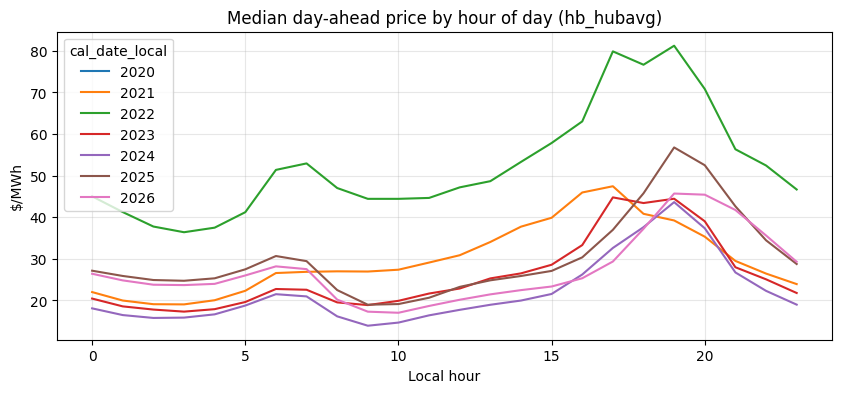

In [ ]:
# Typical daily shape: average price by local hour, per year (shows the solar 'duck curve' moving the cheap hours to midday)
prof = df.groupby([yr, 'cal_hour_local'])[TARGET].median().unstack(0)
prof.plot(figsize=(10, 4), title=f'Median day-ahead price by hour of day ({HUB})')
plt.xlabel('Local hour'); plt.ylabel('$/MWh'); plt.grid(alpha=.3); plt.show()

## 3. Inputs known before the 10:00 deadline

**Allowed:**
- `fcst_*`: forecasts of demand, wind, solar and weather, as published before the deadline
- `cal_*`: calendar
- `gas_*`: gas prices and storage, already lagged
- `stress_outage_*`, `stress_adeq_*`: planned outages and spare capacity, as published before the deadline
- Past prices, with enough delay to be known at decision time:
  - day-ahead prices: 24 h or more back, because yesterday's day-ahead results were published the day before
  - real-time prices: 48 h or more back

**Not allowed:** `act_*`, measured weather (`wx_*` without `fcst_`), same-day real-time stress (`stress_rt_*`) and the other `target_*` columns. These are only known on the day itself and would leak the answer.

The cell below assembles the list of admissible columns and adds the lagged price features.

In [ ]:
# SAFE / SKIP decide which columns are admissible - see the section note above.
SAFE = ('fcst_', 'cal_', 'gas_', 'stress_outage_', 'stress_adeq_')
SKIP = ('_lead_h', 'coverage', 'nbs_share')
base_feats = [c for c in df.columns
              if c.startswith(SAFE) and c not in ('cal_date_local', 'cal_regime_uri_window')
              and pd.api.types.is_numeric_dtype(df[c]) and not any(s in c for s in SKIP)]

p, rt = df[TARGET], df[RT_COL]
lag = pd.DataFrame({
    'price_lag24': p.shift(24),                         # same hour yesterday
    'price_lag48': p.shift(48),
    'price_lag168': p.shift(168),                       # same hour last week
    'price_24h_mean_lag24': p.shift(24).rolling(24).mean(),
    'price_24h_max_lag24': p.shift(24).rolling(24).max(),
    'price_24h_min_lag24': p.shift(24).rolling(24).min(),
    'price_7d_mean_lag24': p.shift(24).rolling(168).mean(),
    'rt_lag48': rt.shift(48),
    'rt_24h_mean_lag48': rt.shift(48).rolling(24).mean(),
    'rt_24h_max_lag48': rt.shift(48).rolling(24).max(),
    'sys_lambda_lag48': df['stress_rt_system_lambda_mean'].shift(48),
    'as_regup_lag24': df['stress_dam_as_regup_mcpc'].shift(24),
    'as_rrs_lag24': df['stress_dam_as_rrs_mcpc'].shift(24),
    'dam_congestion_lag24': df['stress_dam_shadow_sum'].shift(24),
    # simple ratios from the day-ahead forecasts
    'fcst_renew_share': (df['fcst_wind_mw'] + df['fcst_solar_mw']) / df['fcst_load_mw'],
    'fcst_margin_ratio': df['stress_adeq_margin_mw'] / df['fcst_load_mw'],
    'fcst_netload_ramp': df['fcst_net_load_mw'].diff(),  # both hours are forecasts for the same day
})
FEATURES = base_feats + list(lag.columns)
data = pd.concat([df, lag], axis=1)
print(len(FEATURES), 'input columns')

78 input columns


## 4. Split by time

Prices range from below USD 0 to about USD 5,000 per MWh. Models learn badly from such extreme spikes, so we train on `arcsinh(price)`, which compresses the spikes, and convert back afterwards.

| Set | Dates | Use |
|---|---|---|
| train | 2021–2023 (minus Winter Storm Uri week) | fit models |
| valid | 2024 | choose settings, early stopping |
| test | 2025-01-01 → 2025-12-04 | final score |
| test_new | 2025-12-05 → end | final score in ERCOT's redesigned market |

We never split randomly: the test period must be the future.

The cell below applies the split and compresses prices with arcsinh.

In [ ]:
data = data[data.cal_regime_uri_window == 0].dropna(subset=[TARGET, 'price_lag168'])
data['y'] = np.arcsinh(data[TARGET])
d = data.cal_date_local
sets = {
    'train':    data[d < '2024-01-01'],
    'valid':    data[(d >= '2024-01-01') & (d < '2025-01-01')],
    'test':     data[(d >= '2025-01-01') & (data.cal_regime_ercot_rtcb == 0)],
    'test_new': data[data.cal_regime_ercot_rtcb == 1],
}
for k, v in sets.items():
    print(f'{k:9s} {len(v):6,} hours  {v.cal_date_local.min()} -> {v.cal_date_local.max()}')
train, valid = sets['train'], sets['valid']

train     25,920 hours  2021-01-08 -> 2023-12-31
valid      8,784 hours  2024-01-01 -> 2024-12-31
test       8,112 hours  2025-01-01 -> 2025-12-04
test_new   7,943 hours  2025-12-05 -> 2026-10-31


,pearson_price,pearson_arcsinh,spearman_price,n_obs
price_lag24,0.634,0.432,0.807,34704
price_lag48,0.271,0.214,0.733,34704
stress_adeq_margin_mw,-0.321,-0.727,-0.713,34703
inv_margin,0.299,0.262,0.713,34703
fcst_margin_ratio,-0.285,-0.696,-0.681,34703
stress_adeq_avail_cap_reserve_mw,-0.315,-0.708,-0.681,31512
price_lag168,0.081,0.043,0.679,34704
sys_lambda_lag48,0.316,0.274,0.650,34704
rt_lag48,0.231,0.196,0.643,34704
fcst_net_load_mw,0.326,0.692,0.642,34684


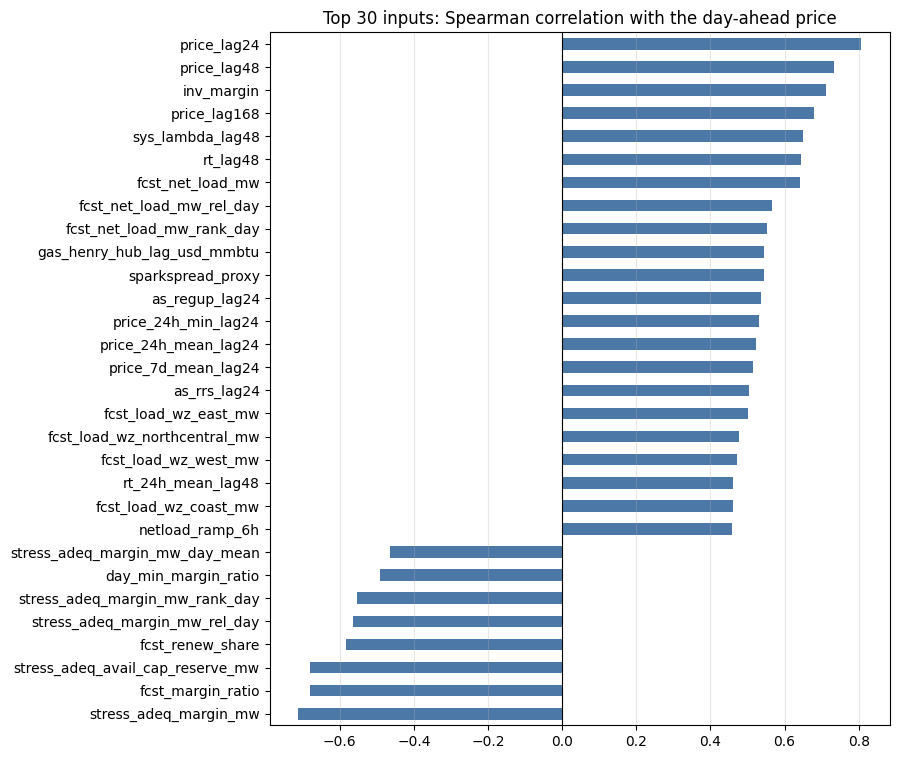

In [ ]:
# Correlation of every input with the day-ahead price (TARGET).
feats = globals().get('FEAT2', FEATURES)  # 114 inputs if the upgraded section has run, otherwise 78
src = data2 if 'FEAT2' in globals() else data
base = src[src.cal_date_local < '2025-01-01']  # train + valid only, never the test period
corr = pd.DataFrame({'pearson_price': base[feats].corrwith(base[TARGET]), 'pearson_arcsinh': base[feats].corrwith(base['y']), 'spearman_price': base[feats].corrwith(base[TARGET], method='spearman'), 'n_obs': base[feats].notna().sum()})
corr['abs_spearman'] = corr.spearman_price.abs()
corr = corr.sort_values('abs_spearman', ascending=False).drop(columns='abs_spearman')
pd.set_option('display.max_rows', 200)
display(corr.round(3))
# Chart of the 30 most strongly correlated inputs
corr.spearman_price.head(30).sort_values().plot.barh(figsize=(8, 9), color='#4C78A8', title='Top 30 inputs: Spearman correlation with the day-ahead price')
plt.axvline(0, color='black', lw=.8); plt.grid(alpha=.3, axis='x'); plt.show()

## 5. Battery plan and scoring

For each day, `plan_day` uses the **forecast** prices to choose:
- `BATTERY_HOURS` hours to charge, then
- the same number of later hours to discharge.

It keeps the most profitable choice, and skips the day if even the best plan doesn't pay after efficiency losses.

The plan is then paid at the **actual** prices. **Value captured** = profit following the model's plan ÷ profit with perfect hindsight. This is the number that matters to the battery owner.

This simplified version allows one cycle per day, ignores ancillary services and treats discharge revenue as `EFFICIENCY × price`.

The cell below implements the daily plan, the profit calculation, and the scoring function used throughout.

In [ ]:
# plan_day brute-forces the charge/discharge split point; fine over 24 hours.
def plan_day(prices, k=BATTERY_HOURS, eff=EFFICIENCY):
    prices = np.asarray(prices, float); n = len(prices)
    best, plan = 0.0, (np.array([], int), np.array([], int))
    for t in range(k, n - k + 1):                      # charge before hour t, discharge from t on
        ch = np.argsort(prices[:t])[:k]
        dis = t + np.argsort(prices[t:])[-k:]
        gain = eff * prices[dis].sum() - prices[ch].sum()
        if gain > best:
            best, plan = gain, (ch, dis)
    return plan

def day_profit(actual, ch, dis, eff=EFFICIENCY):
    return BATTERY_MW * (eff * actual[dis].sum() - actual[ch].sum())

def evaluate(frame, pred, name):
    f = frame[['cal_date_local', 'ts_utc', TARGET]].assign(pred=np.asarray(pred))
    prof, perf, hit, rank = [], [], [], []
    for _, g in f.groupby('cal_date_local'):
        if len(g) < 23: continue                         # skip days with missing hours
        g = g.sort_values('ts_utc'); a, pr = g[TARGET].values, g.pred.values
        ch, dis = plan_day(pr); bch, bdis = plan_day(a)
        prof.append(day_profit(a, ch, dis)); perf.append(day_profit(a, bch, bdis))
        if len(ch): hit.append(len(set(ch) & set(np.argsort(a)[:BATTERY_HOURS])) / BATTERY_HOURS)
        rank.append(pd.Series(pr).corr(pd.Series(a), method='spearman'))
    ok = f.pred.notna()
    err = (f.pred - f[TARGET])[ok]
    mse = (err ** 2).mean()
    r2 = 1 - mse / f.loc[ok, TARGET].var(ddof=0)
    r2_log = 1 - ((np.arcsinh(f.pred) - np.arcsinh(f[TARGET]))[ok] ** 2).mean() / np.arcsinh(f.loc[ok, TARGET]).var(ddof=0)
    return {'model': name, 'R2': r2, 'R2_arcsinh': r2_log, 'MSE': mse, 'RMSE': np.sqrt(mse),
            'MAE': err.abs().mean(), 'MedianAE': err.abs().median(), 'day_rank_corr': np.nanmean(rank),
            'charge_hour_hit_rate': np.mean(hit), 'profit_$': sum(prof),
            'perfect_profit_$': sum(perf), 'value_captured_%': 100 * sum(prof) / sum(perf)}

## 6. Models

All models are tuned on 2024 (valid), then refit on 2021–2024 before scoring on the test sets.

| Model | Role |
|---|---|
| Same hour yesterday / last week | Simplest baselines |
| Historical average by month and hour | "Always charge at the usual cheap hours" |
| Ridge regression | Linear, explainable |
| Random Forest | Non-linear |
| XGBoost, LightGBM | Gradient boosting, usually the strongest on tables like this |
| Neural network (MLP) | For comparison |

The cells below find how many trees each booster needs (using 2024 only), refit every model on 2021-2024, and fit the static price-range models. Section 11 later replaces those ranges with walk-forward versions, and adds HistGradientBoosting, CatBoost and a residual-target model.

The last block adds three further model families, so the comparison is not just "our LightGBM versus simple rules": **HistGradientBoosting** is scikit-learn's own boosting, **CatBoost** is a third library with quite different defaults, and the **residual model** predicts the gap to yesterday's same hour rather than the price itself - a standard trick when a strong lag is available.

In [ ]:
X, y = train[FEATURES], train.y
Xv, yv = valid[FEATURES], valid.y
trval = pd.concat([train, valid])
to_price = np.sinh
fitted, best_iter = {}, {}

def timer(msg):
    t = time.time(); print(msg, end=' ... ', flush=True); return lambda: print(f'{time.time() - t:.0f}s')

done = timer('LightGBM')
lgb_params = dict(learning_rate=0.03, num_leaves=63, min_child_samples=30, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
m = lgb.LGBMRegressor(n_estimators=5000, **lgb_params)
m.fit(X, y, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(200, verbose=False)])
best_iter['lgbm'] = m.best_iteration_; done()

done = timer('XGBoost')
xgb_params = dict(learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, random_state=SEED, tree_method='hist')
m = xgb.XGBRegressor(n_estimators=5000, early_stopping_rounds=200, **xgb_params)
m.fit(X, y, eval_set=[(Xv, yv)], verbose=False)
best_iter['xgb'] = m.best_iteration + 1; done()
print('best number of trees:', best_iter)

LightGBM ... 18s
XGBoost ... 43s
best number of trees: {'lgbm': 2755, 'xgb': 3201}


In [ ]:
# CatBoost installs on demand. ResidualModel wraps a model that predicts the gap
# to yesterday's same hour, so it can be called like any other model.
# Refit every model on train + valid (2021-2024) with the chosen settings
Xa, ya = trval[FEATURES], trval.y
models = {
    'ridge': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0)),
    'random_forest': make_pipeline(SimpleImputer(strategy='median'),
                                   RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.33,
                                                         n_jobs=-1, random_state=SEED)),
    'neural_net': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True,
                                             max_iter=300, random_state=SEED)),
    'xgboost': xgb.XGBRegressor(n_estimators=best_iter['xgb'], **xgb_params),
    'lightgbm': lgb.LGBMRegressor(n_estimators=best_iter['lgbm'], **lgb_params),
}
for name, m in models.items():
    done = timer(name); m.fit(Xa, ya); fitted[name] = m; done()

# --- Additional model families ------------------------------------------

import importlib.util, subprocess, sys
from sklearn.ensemble import HistGradientBoostingRegressor

if importlib.util.find_spec('catboost') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])

class ResidualModel:
    """Predicts the gap to yesterday's same hour, then adds that hour back on."""
    def __init__(self, m):
        self.m = m
    def predict(self, X):
        return self.m.predict(X) + np.arcsinh(X['price_lag24'].values)

done = timer('hist_gbdt')
fitted['hist_gbdt'] = HistGradientBoostingRegressor(
    max_iter=600, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=30,
    l2_regularization=1.0, random_state=SEED).fit(Xa, ya); done()

try:
    from catboost import CatBoostRegressor
    done = timer('catboost')
    fitted['catboost'] = CatBoostRegressor(
        iterations=2000, learning_rate=0.05, depth=8, l2_leaf_reg=3.0,
        random_seed=SEED, verbose=0, allow_writing_files=False).fit(Xa, ya); done()
except Exception as e:
    print('catboost skipped:', type(e).__name__, e)

done = timer('lgbm_residual')
_res_y = ya.values - np.arcsinh(trval.price_lag24.values)
fitted['lgbm_residual'] = ResidualModel(
    lgb.LGBMRegressor(n_estimators=best_iter['lgbm'], **lgb_params).fit(Xa, _res_y)); done()

EXTRA_MODELS = ['hist_gbdt', 'catboost', 'lgbm_residual']
EXTRA_MODELS = [m for m in EXTRA_MODELS if m in fitted]
print('models now fitted:', list(fitted))


ridge ... 0s
random_forest ... 44s
neural_net ... 19s
xgboost ... 26s
lightgbm ... 18s
hist_gbdt ... 8s
catboost ... 39s
lgbm_residual ... 23s
models now fitted: ['ridge', 'random_forest', 'neural_net', 'xgboost', 'lightgbm', 'hist_gbdt', 'catboost', 'lgbm_residual']


In [ ]:
# Price range: LightGBM quantile models (P10, P50, P90) - tells the owner how uncertain each hour is
quant = {}
for q in (0.1, 0.5, 0.9):
    done = timer(f'quantile {q}')
    quant[q] = lgb.LGBMRegressor(objective='quantile', alpha=q, n_estimators=best_iter['lgbm'], **lgb_params).fit(Xa, ya)
    done()

quantile 0.1 ... 21s
quantile 0.5 ... 20s
quantile 0.9 ... 21s


## 7. Results

The cell below scores every model on both test periods. The three benchmark rows are the bar any useful model has to clear.

In [ ]:
hist = trval.groupby(['cal_month', 'cal_hour_local'])[TARGET].mean()   # historical average by month and hour

def predict_all(frame):
    out = {'naive_yesterday': frame.price_lag24.values,
           'naive_last_week': frame.price_lag168.values,
           'hist_month_hour': hist.reindex(pd.MultiIndex.from_arrays([frame.cal_month, frame.cal_hour_local])).values}
    for name, m in fitted.items():
        out[name] = to_price(m.predict(frame[FEATURES]))
    out['lgbm_median_q50'] = to_price(quant[0.5].predict(frame[FEATURES]))
    return out

results, preds = {}, {}
for split in ('test', 'test_new'):
    preds[split] = predict_all(sets[split])
    results[split] = (pd.DataFrame([evaluate(sets[split], p, n) for n, p in preds[split].items()])
                      .set_index('model').sort_values('value_captured_%', ascending=False))
    print(f'\n=== {split}: {sets[split].cal_date_local.min()} -> {sets[split].cal_date_local.max()} ===')
    display(results[split].round(2)) if 'display' in globals() else print(results[split].round(2))


=== test: 2025-01-01 -> 2025-12-04 ===
                   R2  R2_arcsinh      MSE   RMSE    MAE  MedianAE  day_rank_corr  charge_hour_hit_rate    profit_$  perfect_profit_$  value_captured_%
model                                                                                                                                                  
catboost         0.70        0.73   225.28  15.01   7.29      4.72           0.93                  0.68  3198156.30        3294332.59             97.08
lgbm_median_q50  0.70        0.74   232.15  15.24   7.30      4.48           0.93                  0.68  3197639.39        3294332.59             97.06
xgboost          0.73        0.73   204.72  14.31   7.19      4.41           0.93                  0.67  3194986.48        3294332.59             96.98
lgbm_residual    0.68        0.73   247.55  15.73   7.00      4.29           0.93                  0.68  3190835.96        3294332.59             96.86
lightgbm         0.72        0.73   213.04  14.6

**How to read the table**

| Column | Meaning |
|---|---|
| `R2` | Share of the hour-to-hour price variation explained (1 = perfect, 0 = no better than predicting the average, below 0 = worse). A few price spikes pull it down a lot |
| `R2_arcsinh` | R² on the compressed price scale the models were trained on; less sensitive to spikes |
| `MSE`, `RMSE` | Mean squared error (USD/MWh)² and its square root (USD/MWh). Dominated by spikes |
| `MAE`, `MedianAE` | Average and median absolute price error, USD/MWh |
| `day_rank_corr` | How well the model orders the hours within each day; 1 = perfect order |
| `charge_hour_hit_rate` | Share of chosen charge hours that really were among the cheapest |
| `profit_$`, `perfect_profit_$` | Battery profit following the model's plan, and with perfect hindsight |
| `value_captured_%` | `profit_$` as a share of `perfect_profit_$`. **The headline number** |

The four cells below chart value captured by model, show one week in detail (green = charge, red = discharge), rank the inputs by influence, and compare monthly profit against perfect hindsight.

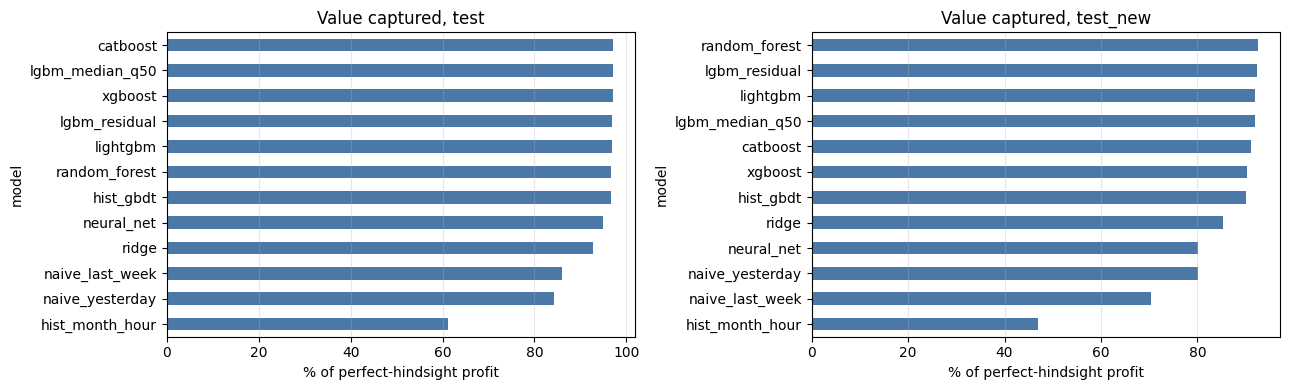

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, split in zip(ax, ('test', 'test_new')):
    results[split]['value_captured_%'].sort_values().plot.barh(ax=a, color='#4C78A8')
    a.set_title(f'Value captured, {split}'); a.set_xlabel('% of perfect-hindsight profit'); a.grid(alpha=.3, axis='x')
plt.tight_layout(); plt.show()

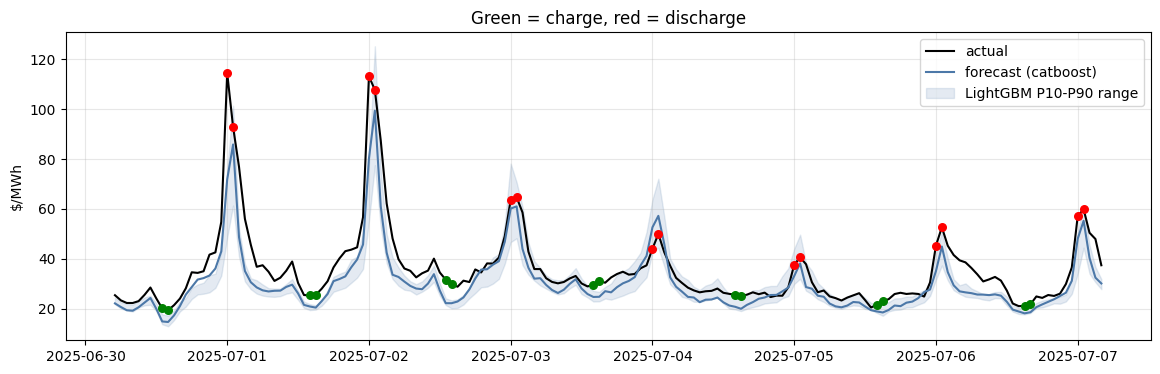

In [ ]:
# Change the day slice to inspect a different week.
# One week: actual vs forecast price, with the hours the best model chose to charge (green) and discharge (red)
BEST = results['test'].index[0]
split = 'test'; f = sets[split].assign(pred=preds[split][BEST])
days = sorted(f.cal_date_local.unique())[180:187]          # change the slice to look at other weeks
w = f[f.cal_date_local.isin(days)].sort_values('ts_utc')
fig, a = plt.subplots(figsize=(14, 4))
a.plot(w.ts_utc, w[TARGET], label='actual', color='black'); a.plot(w.ts_utc, w.pred, label=f'forecast ({BEST})', color='#4C78A8')
lo, hi = to_price(quant[0.1].predict(w[FEATURES])), to_price(quant[0.9].predict(w[FEATURES]))
a.fill_between(w.ts_utc, lo, hi, alpha=.15, color='#4C78A8', label='LightGBM P10-P90 range')
for _, g in w.groupby('cal_date_local'):
    g = g.sort_values('ts_utc'); ch, dis = plan_day(g.pred.values)
    a.scatter(g.ts_utc.values[ch], g[TARGET].values[ch], color='green', zorder=3, s=30)
    a.scatter(g.ts_utc.values[dis], g[TARGET].values[dis], color='red', zorder=3, s=30)
a.set_title('Green = charge, red = discharge'); a.set_ylabel('$/MWh'); a.legend(); a.grid(alpha=.3); plt.show()

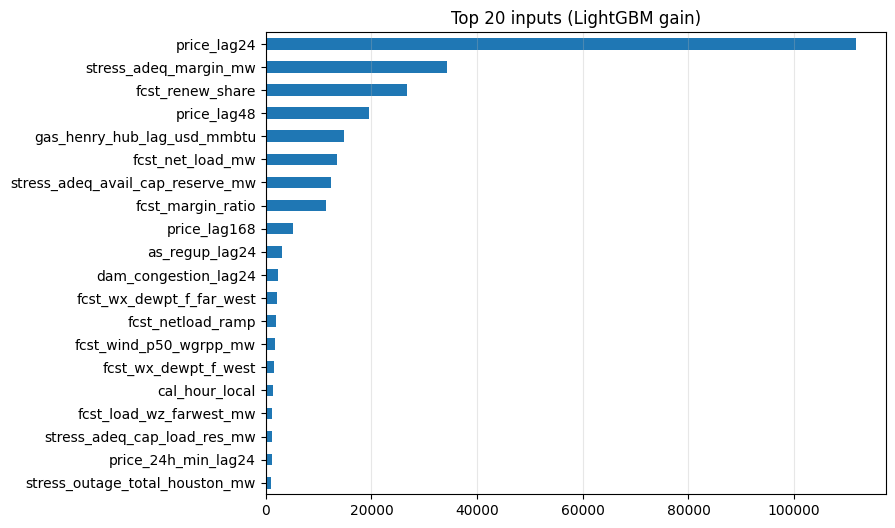

In [ ]:
# What drives the price forecast (LightGBM, total gain)
imp = pd.Series(fitted['lightgbm'].booster_.feature_importance('gain'), index=FEATURES).sort_values()
imp.tail(20).plot.barh(figsize=(8, 6), title='Top 20 inputs (LightGBM gain)'); plt.grid(alpha=.3, axis='x'); plt.show()

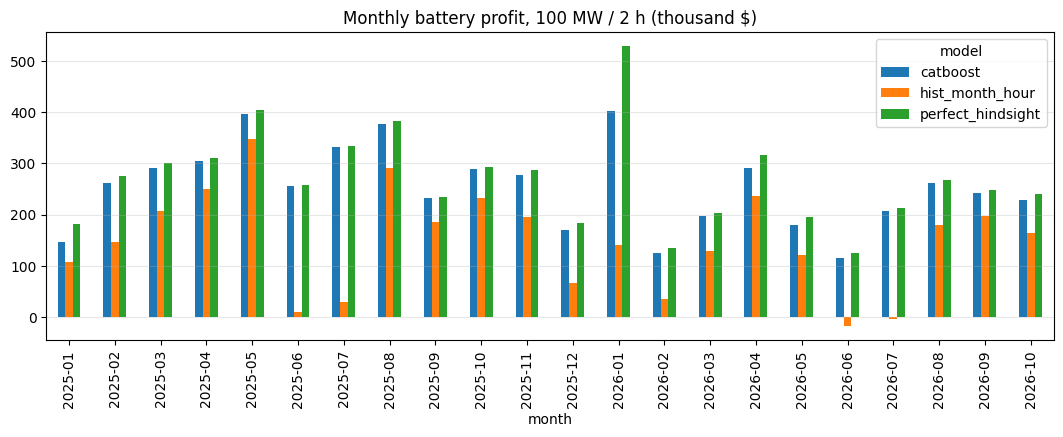

In [ ]:
# Monthly profit: best model vs perfect hindsight vs simple historical rule
rows = []
for split in ('test', 'test_new'):
    s = sets[split]
    for name in (BEST, 'hist_month_hour'):
        f = s[['cal_date_local', 'ts_utc', TARGET]].assign(pred=preds[split][name])
        for day, g in f.groupby('cal_date_local'):
            if len(g) < 23: continue
            g = g.sort_values('ts_utc'); a = g[TARGET].values
            ch, dis = plan_day(g.pred.values); bch, bdis = plan_day(a)
            rows.append((day[:7], name, day_profit(a, ch, dis), day_profit(a, bch, bdis)))
m = pd.DataFrame(rows, columns=['month', 'model', 'profit', 'perfect'])
tab = m.pivot_table(index='month', columns='model', values='profit', aggfunc='sum')
tab['perfect_hindsight'] = m[m.model == BEST].groupby('month').perfect.sum()
(tab / 1e3).plot.bar(figsize=(13, 4), title=f'Monthly battery profit, {BATTERY_MW} MW / {BATTERY_HOURS} h (thousand $)')
plt.grid(alpha=.3, axis='y'); plt.show()

## 8. Example recommendation for one day

In real use, at about 09:30 you would load tomorrow's forecasts (ERCOT load, wind and solar, the weather forecast and gas prices) into a row per hour, then call `recommend`. Here we demo it on the last full day in the data.

In [ ]:
BEST_ML = next(n for n in results['test'].index if n in fitted)   # best trained model

def recommend(day_rows, model_name=BEST_ML):
    g = day_rows.sort_values('ts_utc')
    pred = to_price(fitted[model_name].predict(g[FEATURES]))
    lo, hi = to_price(quant[0.1].predict(g[FEATURES])), to_price(quant[0.9].predict(g[FEATURES]))
    ch, dis = plan_day(pred)
    action = np.array(['-'] * len(g), dtype=object); action[ch] = 'CHARGE'; action[dis] = 'DISCHARGE'
    out = pd.DataFrame({'local_hour': g.cal_hour_local.values, 'forecast_$': pred.astype(float).round(1),
                        'P10_$': lo.round(1), 'P90_$': hi.round(1), 'action': action})
    if TARGET in g: out['actual_$'] = g[TARGET].values.round(1)
    return out

last_split = 'test_new' if len(sets['test_new']) else 'test'
s = sets[last_split]; counts = s.groupby('cal_date_local').size()
day = counts[counts >= 23].index.max()
print('Day:', day, '| model:', BEST_ML)
print(recommend(s[s.cal_date_local == day]).to_string(index=False))

Day: 2026-10-31 | model: catboost
 local_hour  forecast_$  P10_$  P90_$    action  actual_$
          0        24.2   23.2   25.9         -      42.2
          1        23.3   23.4   25.6         -      40.8
          2        22.2   22.9   23.7         -      42.3
          3        22.0   23.3   24.3         -      41.0
          4        21.9   23.0   23.9         -      41.3
          5        23.9   24.9   27.8         -      42.8
          6        24.1   25.8   29.0         -      43.8
          7        25.9   27.1   30.8         -      46.1
          8        25.5   25.9   30.5         -      48.2
          9        22.9   22.0   26.7         -      45.7
         10        21.5   21.1   25.1         -      40.3
         11        20.1   20.6   23.9    CHARGE      38.3
         12        20.6   20.7   23.8    CHARGE      36.8
         13        21.2   20.2   23.8         -      35.6
         14        22.8   22.0   25.5         -      35.6
         15        24.9   24.2   30.7 

## 9. Optional: chance the price is at or below USD 0

Worth doing at **HB_WEST**, where 4–8 % of hours are at or below USD 0. At the hub average it's under 1 %, too rare to learn. Set `HUB = 'hb_west'` in Settings, run all cells, then run this one.

In [ ]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score
yb = (trval[TARGET] <= 0).astype(int)
if yb.sum() >= 50:
    clf = lgb.LGBMClassifier(n_estimators=best_iter['lgbm'], is_unbalance=True, **lgb_params).fit(Xa, yb)
    for split in ('test', 'test_new'):
        s = sets[split]; yt = (s[TARGET] <= 0).astype(int); pr = clf.predict_proba(s[FEATURES])[:, 1]
        print(f"{split}: share <= $0 {yt.mean():.1%} | AUC {roc_auc_score(yt, pr):.3f} | "
              f"precision {precision_score(yt, pr > .5):.2f} | recall {recall_score(yt, pr > .5):.2f}")
else:
    print(f'Only {yb.sum()} hours <= $0 at {HUB}: too few. Try HUB = "hb_west".')

Only 18 hours <= $0 at hb_hubavg: too few. Try HUB = "hb_west".


## 10. Next steps

1. **Tune LightGBM** on `valid` only: try `num_leaves` 31/127, `learning_rate` 0.01/0.05, `min_child_samples` 50/100. Look at the test sets only once, at the end.
2. **Change the hub** to the battery's location and re-run.
3. **Add the wind and solar site weather** when it arrives: capacity-weighted wind speed and sunlight, joined on `ts_utc`.
4. **Real-time prices:** forecast `target_rt_price_*` instead. They're more volatile, so batteries earn more from them, but they're harder to forecast.
5. **Walk-forward test:** retrain every month, forecast the next month and repeat, so the score reflects how the model is really used.
6. **More realistic battery:** add state of charge, several cycles a day, degradation cost and ancillary-service revenue.

### Building the upgraded pipeline

The cells from here down implement the recommendation memo: monthly retraining, a ranking model, a spike classifier, a sequence deep-learning model, blending, and a realistic battery simulator.

The cell below unpacks three Python files into `/content` holding the heavier machinery. They are stored compressed inside the cell, so the notebook stays self-contained and needs no external repository.

In [ ]:
# Modules are gzip+base64 inlined so the notebook stays self-contained.
import base64,gzip,json,pathlib,sys; _f=json.loads(gzip.decompress(base64.b64decode("H4sIAAD8+GoC/+1cbZPbtrX+K5zktiJtSbtavyWbKjNpnNSdu3Y9sdvaI2sYSoQkZimSISntKu72t9/nOQBIUNKu7ST9cO9ct45FEDg4ODg47+D7z2Z1OM9L9dm599k7+d/o0fD0ych7WeY/qXntjbyB91pdR5U3i+palTuvKJO58tZ5rNJzL5rPN2U033mbYllGsaqG77K/rotUrVVWV16RRplXAU6SZ5X3cDjy/KsovRws8vIqKuOgj7YHnr9QUb0pVSXPDz2/KpJL5d33ft5EWZ2kqnqX3ffSaD2LozLKLqXbI3Sro/llki3l+czzozgq6mSrvDhK0p1XKky/C4DRN2nqVUWaAKOoVF6drNUgL2NVqvgrL8vrFYB4m0pVXhXhVRztsLA6PLm6Dk+qGohVYVmH3jxPN+uMS9Skepcl6yIvay/brAsMqbys6HtFlMX4if8Xcd/DMjNAr/oy67vMPg8XSQpy2ke/lywz7EMvaICmyXJVL2drQkqXM0yaXfzlz+H337x67Y29OJnXfqr08LCMajU+HZ4+6hOXEO1bVY0fP+h76yQL56skjUMsDftSjR+c9r1qM9OPGPRF/13m7f1p3oeLUv08HvW5dtMy24EieiBIvAz1voxHw9MjgLBdcb4OsVNA8OFZ39uqcpZXajwAzCz8KZ9V+BlwcU+/eRt++7eLV1jcpLeYV3WYqTpM8ygO11e9vqfb9p+rPI1Kt+EqyXSHLjI9s4/g0Z/DdVQuQRf0mnLmd9nn3uA3/hFGtnz8LovVwoviOAQrhbbVjzUZxy/yTAXnGj/NSf9c5anmO5wMNY+q2ouWS1AXZKtwEFQ0X3mrfFOC4mkkPF7nHvk5v8rA7jvypMD7bsszmmTFpvYScKEnRLl34i7/nuHkvpcM1dArNrM0qVYq9maK03v1Smlgo9Pz01MvVlGcJpkibnznXRFbL18Ah3VelvkVGCrH+eEp4nvg06u8dXR9Au47WavI4AZ8UrVMcBCwrHPpmhcKvAu4lcJCI5zTs4ctDbhitNZens3V0CWY/k1qkl3mgtocy/Z8acOTZafASxb6VTw0B3iqRy/7Xg4q4SwNl2W+KWY7vzePUuxZrcBn+NmDZHl/o3s3M3CC85a54nUff6/5nwywlpP5dFiD7SsMWPs9rp5gDtqj66PNSUYRYIEDPyzuvtcTRhJYUyK8vrULwOoe17d2SSyQ7LYuZba0UCD+b+kITmRn3RHLkJ5HO0JkNz1lwWzxi3k9fl1ulFnu556W+gX2HrueY+N9nCnzFnt4KBM6m3renbqHjtKvhNQKH6wMmodApsM4WSz8B8Fd4x9/cPxjB9HjoqaDrQe5uCfRbluNYavbBNgHuKdnttwOwWlLclkM4J40K2pWszc6ybZmpIyBkNeDbkNmniaFn+ZXqhw/Oj01uCyj/VPa0oGHcwj1UNbVVVKv/B46h+4i8Ie0KuJhVCTDelfAxkiqEGpOwRAJY7b45L9A+vHXECo9i/xgyAPjB97X3vDRtNkeTLDPK5zzJ+jw8Els9hktk9Op2dvR4y8chBpW/NDGNeCrIiovKzA2+hdlfr3rTuLd857AnOERgOpPEwhiTdIohbCp6r73b75//vzP9ebk+T9XeoZMXQEIyPI0qqPvwaXKx2QQ6dA91+N4KP8atEsFBZSx8xySNKr9CVQRAEz7XnSdVOMRJBFUQO2jzS4k+PWaUQw9184jAmWU0FTRqjFc51m9gkakfoP24P5bjbgmbdg+jOthnYfQEEke+73nve5q1tQ6Za1ifz2R/t7XQo/XsLMAcF34Gux0uMmSnzfKD8ySBIErRfOq8gWv0OBRqkXfW0XpIkyTRaOiseFgqLbd2WKDChW6boyWCuj7AARx6MAOuBgcxWq4jdIN1gb1RsZdgInq7rpOsdf37sGaBagTB5sWeZI2NKQlCaN+Y3kYWsLaBAepetzb9WhngSBUuhCq49HZ6SmNVHCMtkSOWG3trLoHbO+ZSse9Xmu/ieTu2DA/6D22RoQSQ0T2GepbVDs8BwgAg7DV8fUK+l26NTbMD0IIGi+vsPfYWIynsRCVc9gYK6+CagZSL6IXPF9VEittlrgcRzMwvzpiMxTWeLbGdPCVVww3BbfJ12Sh+fD+xuxKXFf6nIEV2YdmvBB9sm8sTM0IWUxf/8OxDbPXDasbVOB/aNh6nX5WDLMoa84wJtHHGMYFuWXsckt9iqFEZigYBa2VsqZA0nM6rFoLY+r9GEP6B4YTnR4le3C9f/LWWiaHhH3YEyeiLofVZg3h+icPgv6UJKuVaQL40z05CLlTJ9lGta1wMfRBjyZ16aiddZyiHQ7PEBv0/Ae1pKLJS7/DxO5DH6elCDoA4FzVPiaY2GMxFZdnog/F9JjDo30bLRXGjXQAMYhdv0MPV0Q483I3hwlYYYJtXMBKz/LsF1Xmfq0C0bfAi33Ie7K17Fqr9uxOWxPCnLJzF3qS1f6i53VO/+S9nMyb6bn3PlWZ3t4quDHbD+vV4ZBBfXo+PF3cVDjGi3RTrVzzy6oIIHhc0IgZd5u0+XQJI3+MWGk9+zsFzAX3BDzhRAJgwcMvEevdg56Aq5ImInfoSvmMJcRqnlSIPkAwzOHhx0EjZS7oPFfaC2EsgN4LfRo8wwcR1wPu+yqB5wXH5Ypiiu9sGAQBgg2E2k7iBsOu4CqjK3q+jE1AWEHSwZalConzFN5qFUA3FFFSerR4pGMI+ZHM6MX7we8gs5p3+YxBHJBkj8hryOpkPu5l8XzZM+I9XEJ6j8UMQK+l8s8eBcF/Xghyp4wcOIDVETxCyP8Xl3viEluHdry93YedwAgwPhf2fZXH494iKau6F1grBKKFPDnaB4v/aose5/nM9ZCWZfGBWbVxNv4+SitQpEp+IWfvE2ZP1gND9dsFPZDua5EwBppOf2Gg//USWlbRiug96SHB2ZCL6OtX0r3PU9YVpi83WpyVWsFCQuqQLgI3hgSwTXSo914KWy6t7kHWIugkg2Sn0PWeSM57jUz9b6WKyoo5j+4XROBikyJWm0swONSxIXhB2LloliAmu/MY5YJMSGAiXuXwlAKK3dQwfx1d2rgSxWWSSZiskdiLMl87OB0RnjrGc5vUaAl2u+xY7Dta73tF79xzad2r0OASvBejAZjeOJImBF9S2CzaUxP3gvOOoICjX+C0JpU4sFG2g4DAUPr/e80fFBl624A7VszD6BvY+hQGXVX8OcLMc5XFpOkeAzgHVsiuIcKUEqDOT4OkgR8QKElCrdoGMGc7y8KOjywnbal3gCdRoz6R6aYd9kfn3yVkK4kGHXESvj9i8MjbW/2rVYlIOkLu1tVCGiW929rpWklf7BtJd1g+L/W5RiAD0wZi6ZCWfetXM2JAcZLuho0NgiM20wcsoX3yW6wJhIGqcJPNIhzguZLgBXH8j5sGu1lIt5FaVvReQ+epoYSrv6xLlc/+r9oIbNAkoQnQ9H3wYeOhq2e/TSMI/EXya3RtqxZLRy32Hbw6HlE++0h9Gwq73qZ1J+d9bzT9dN0rJ/jr92AVUavUwZ/sD+WzVtkKPDDgeoYz5xP1EEm7dZT2pWNfJGe4gp8Cz0G7koiYds/yd9eFEtkqHHDu+aNBEdzTYBAuL+6Z4XQNCh3qiCk0f9QAfzw4yqCt2GgUxFVUltHO18ho1kZ0UY/sexA4o6AzEEcjxLlFMNUvugv3mfgtOLoD11mxAQ+Uj3TSi7CH6zfJa5HUNhMMusSqjSM2hk84Q/AXgWcmPKGOV0nfOGhNJAz5yr2deEXaiu3wcnQ6ePnlqUcgiDLlG/zD9jV4EwnsDafGsQLfMSi3Yt7tRw22ux3d+cnhEaLh4nh51+cuka4tcfreMayt35VfAsi/ubXU/Bm6Bt6/vOZxlXQeo84TQFowM8Uo8ozAtKoBV7bC7ZLCTdS4uH2IP/a9x8NTJGiZUXbtDJCA8swnbLDHJTbe/ARikEVjDyj8EaFL/pQ393WnVYI+glAQTPLLqYnMO1k0wI1mlc8ZBmbLujF3roGOOBdASRhD9LFtT/g5SwVFL22esIP37KMQn30Yc3NWZpdM7G5/L7vkkWcLGzSTZ1lahTM4D7H/EpIWWj+Jl2o8UoPHXYYGaQYZc8bMD6MGAASrcHAYfjABLR1theZg+hjFGBUTDsy5SbEHBA3S6VtoJ5epxcKu5kmxG+Yor1jDlfNs3QMwO86oL7WROupw5M7yIxLGIQUQhvsvSVUsi/+07tWVVW9d3/hKiy2wAAYOq1VUqMlo2t2NK0TNzfBftSNSS7JXSqKNI1NRYrP7ukeoG7XYixifxmLsD22lwQ3AwU6LVQQpNIIUVrWul4D8KtD0aD+QToAmk87Z0zwvzmn1DcSC/u6fz7/xZknEwoBnCqzQ7C4llDZnq8Yla/HyoGxgCT0PbCB9INrFmvss0QFv5VeVZ2pjqHZ01Yob3JJIPBev4j1ANqZ/xAl7aZwGV0cYGrkW2K7bbXesD5eAbmb7DUM5fIH1nXjPjeDT7TQ6Kv/sYeB6hLRJNmlKkmhNaANSR9y9pHfuSMgsaP07/Fr1OqJd77mEVP6ASOIxBzDueIAmVOKa/XIKYiiJ1Uonf5PGr2LNAKacHliQ2DmSZYJx047kbM4feuBYYskf9h2v1ppCVyswgr8HAQf7NBDtADulK6Wv1scPrgvzYJeal/jPSQOifSeyrzFY+JJrhV2zbvKX3YQuSYD+ehzk/WS1ckiyI5ft7qDTbvexLrYqaeA3Uw4I+/gfuMIKxgoi0ByUg0M62SxnsUTWMevEEBPhQWNMv72vG/AMWH1vADEissQhQ5pXVUMy0VlCNGJIa5paFBlz5BnPDA1PbxtsDUQ24qhE2dgAja6lLWhot0CGFy6kNJrQBSSRorURdGX4lTYZ1XXhDyAMqWhlzoFMPUS9gh8Ee5zlMBb1P+Pp7qy3sPbVXTznkNnRGjCP1OChptEB3o5u6UYl+tRq8BU+63ssqlQ4nncWVUKFwtbz2G/DmgyY3G61JLTQExrXr55985KZjMc6cfGDMFGdzG0e4tyT2jrGWOYrmk1wQlh+caIyVS6hO6Cw6VdjLYMraBW1WCTzRGXzXZ96jEWbenZdaRCxbivbefPdPGVBloTnIy30dTDI+2mD+ReINLyirQB2vsY6oKVmVIy7LFoDORgUgLxeS06FSgmAkmoOaskJ2EPZ8wn+4uzk4gsoDW1kVILVu4yp37xg36jRL+8+g3BUiMrEtAUxF1RjyqK3qkaJhU3icMWyDG+lNqUQLfiE0k1S+8V3f8GmD0Zq9MVvMO7MyXc2jRv6JNB2RFwgZIjiu01qorfYrAJlJeORji4p/F6Nz8zDYkFH5gmWrpbjMzZlKIGc433Xhvgbicj6ESHwCYmvSU01RKpxX+HmyNbo4FIRHUnBN0bHEkanZ3jKRxFK37s/2+xwHAaVSlNde1MhcqDigemFCaEsjS3wSip8pBdkcuWpdYHAL4LCrImQolx41Yw9QWYfS4CV+/aDJpRrF7yWuGGGd6aBgkUHP39GcBKkC26VzVIc7InjN0BmrNAScIbKYAQUdjYBVSu6zbIhWLgQ/hZ4IJBE6V797VsZpgFcQmSKU3jtj8RC8GVGn9sNgOwYMGwKAHYgjmO+JVFoNnDfuBmm1GReVzYUK2bJgPD7epb7jaf/ORRDpbGJtGSBB6B3nA5AE1/QTQjSqNJUUrXCwRhTm51rFMj8XzOoIL/uafqckOxiGwT7BImRFs20O0FuMkRVEuHrQv0ToQ5csPcOwRqgOuOrDDiEejaGKPAmCSEwIPT7fziGn/+aZDInSCgGmf/dXwzd/jF5jfmoiTGpd8efz701JKJHNQQ6C2NrCN+4xqf/ujuRjj62gcsqFMK4+9l2by3ImnygX79mxg5kkr8dL537DRO2nNSsLRMKD5pH7uKAm4vfQq1mGT5Pj5CsH7jQrO2lidZg1fea/h3CWVQlBAJslZTqMbYsfff0cwXzgqlEvXwYNnv1c/QrfemE6q5TcdLlCWaAYNKtFPSya5r2/5jUGkN2pWM53TPksCY04wxOO2YuBgMupf4J7SL86As1JwltLrx2ZvsHyTkWUEM50c67b/Q7rnciHSB6dR+DCK34kiGfmMQck90bTnkduA+HnLLPBi5FKfAwORburJhzGITcDG4S60Y/6pxdMeciHmxtvLWv7+nXZJX7ZCPwnTCXk2H17jeTGMuoXWZfoIjz20ZUof10LtC34bq9ro2m6+q3b8njwjLlJmM8kOZBck3bwihTlOJFtAhc00WiH03hBtzHAroq7kQ7oq6i0di4amZfChoReET+3SLgrHQ7Ito6lJNJ6XrR3HRQsoRqwru+OeHALGiOtpWAVvy5xY/G5mTowhgm/oKOro5f08bnbx2E+xhj5NaE14GR0jch9CZ7tpfngrVBw6Q1mGC4wC6Zr74yVKkYvEJ17I5xZ9ubIQueilme1yhMxraCIboxLOyALHEyOSxU6NXIbtXznl0yyn6ZIFlmEqYY74UtLOHtZnFyFDdP28MpUYH9RO9+UUY360tJumQy5+yByfZyqk9N+C4ZK5BUb6iDA75dWtAVEUtbCXcQRAh5AMO1cwAZSHVM1BY1G44gfxjOEJ6QE9s/kM4aMmCGOvjnAo0+GgrJPZRzG/u+ENqRIAe4C5DgNv7cH1l89MjmaBo3OILVBvXU8HZTNrUfSSL6fXuPbCzF+WRAjYb8UuUCDiB/amhyb8LmJ3MeR0nAxxM7aGqdVjaZ0dMjLur7nq7vODfHm3OzaIGsx4t4Bl74X2iTiSw0acHv/QtVsv8oPSmYpIvDP6AXpAStCnjmJ4InOJv/iB7R1LoBnq0gag5suJ37cvFE6JNRwlBWKBy/h2ddGfHloz943/5VDppg4FkMmA2XMk5qA31FSZwL8bU60sA4E/pu2hCIRJu05qUXnzPaDFnf+1kqrjRWDr0t4zuvGrq75wnFLtYlaQPb0tiNjdmMm01Vd/+1Q2O6DiWS17VaqrLyRapi0SytGksQM2zyPVvaFHozColMCT+MGP742X3uZvwarpZw0XZOs65pwxJRHsIUHN6gGgxB6ztef/lkqIsH7U6z3BFM0my4nIQw0vHmcPaBPTf7rTU5d8HjvQxoU5QjIONTXymFMMFVbmLftl6clzmFBzq7TyNbz46FQgr6FoU8G5sDWW0WNCaqsd8LI57FcNZzzzRuHNjjEvUY9mufZzitHS4w0j0OPm3b97b/o1i2EsHQ5RF7vBs20Q1BcBcPxFp+3LLB1Z3bX9nd35MXuq9fSQDPXs0Jgt8jaebNYDBcDlAzlLmRFWllY4gLZVu1b+PAbWyNHF1wZApxDA+yBuLyqsuJT8Up1lnj9gpDLlcOshzBLXGd4QviBgLNPdzRZFgEfvwM1Qy2kE0mh+XKWIebPrYFW+aHsI7+VUm8U3KfVppCzsE2mivuMlyd0ehTWKU4zMfsZVlkMZQ42Nv1ppY4AATZrREUnrXm2hLMNoRRZhsOAq1zj+ZUZDyFWVQpbQPcboia7enJv712n2RH3CyOa3hd0ObSFHPvzyWUnBJGv6A1XMB0vKCFzBU6vsuHUAIckAh37K7fX5wPR4ub42jZijZjpLzvyTwhklW43X3uXfSPak4okYPW6S3mh6upG72Ep+nNrRksINS8m2iihu04pkqwJy6otjP5FtftZB/k2trC7Qfv5/hQI1BiGHLs8Htds8ZhbyPipigHflxovAJfFEDfe9NnlE2083G9YqK/HKsb3vDcvRnqeyA+ExAWgBaZbyjvOrfZ5TRZ8f6GtwztCH1E35go5HVB/48zDV/j4jzqf1KW7JUaVyu6WaDArpLVtOb7mypo0N2vaqN3V22NIGU6Tle4vamaC3wdT6Cp7jQl2d2a4i1IhoVimiaBEd+dvohR6Tuw3x+Q4C1kU1bvJTHwAQKG8xl01PmLVwo38bL2+xGUhill6BNtrCF2zwhnKjc4BtGK8XzjvPMapo6JogIS5VrvMnv9HAXF9sYGATRyuS3atCluxgn0HXMDtL1b/u2LF/f/8sPfEa6a5wyLS9qiiR2gNofRbfgbr+11Wxq2pq8u1sqrhEulmJMXTfLDXClpLqdoTP2LLwYXX3r2YmTfuxiNGC1YDJgkyAhK0+yF+UCF6BN9Tz7b6ab26n60qM1M3Uv754dreJdpjWQutDBHCqo9ZSARZnOlHNKDeFAeLB/B1O1k2M+ng7NP+g6GriMw/YDFHG6e/DPMMhkhAuLpdwzQ6vZYbYE0POdNHPWkPlKa+cgLwNEWtRGMjNssY29ebHrB71OEwzpEObJNEc5sw29o0OTH3vB2+kFhsHvjkjssBcHi98tT1+838Y5km+tNMEwvqoaZgZw1rztaWkhEfh8004h50bwKzKRdAzc2F0UgCIqd9QLjicVJ3z1untwa2sPLHgJrGCPFFsYbuFZzXmb1jwRRGnjttZ4mO0ELw1zVjY9c8mmu59qhCQa+3557iY0jb7txZMIOblpr5xhQVt7FSbB33baNos73qHBbv6fGhZM5japww+FP9RaxS/MVm6A14nXwVspfYVs9ODMg3h6A+PCYNxOk+uFbnesNbKpjhzo/j63eH0gzSsv/cceZeCuQNBgbCPpkIMRdr6JJwb8NrJ+JYAgiWY55uKkkieXez6u6hoKwNPT2276Abl3HNYz40Igu/21fpBgPYjV+0j1N5ljwtj4FWkEVYMS8udhgPk5iryhbbDqnhxv+1pSWnRpj5u2BQYWlwkXE7pn6k+Gs89RQ82AXwWycYDHE1nEOH7kb78N/PrfhvnxTWWFRiS2gwT7bY6iGSDB0P4a55KC1SYVmeN976sYdn00kY4JFTHwWRjb9ApnnPJF/uibgs9/P9hvYuxpzlrB7L/Pqu2zuZ9nwec44osVULviH5MkwZHCcwcRkLTGGh+5qqg18G0RXm77uZTEMGyopUhy+5J0IBf3qaxVEMzBjCjcTwFw7QtlngU2ec357PV9Pfx0cOv5M0upZNIH0mmAgvSTPvlD1Ry0sk88LAY/xl4+x7VDa1ZjyKNohADDG6aXsZtnhJy2c+6rXrg22OolSfy/Tlg2/zbPtKCYhKCYeUeXHYmKekeGy4Q/q4u/+fhygHcdBewMfkqCp+JpdIPsILnWaNxvCZBNAjx/S0UCmIJS7jW4pfzNowTrXg2Xh6QKGUsTbEIaWHfT58ymICB/KJzEPcFm1YA0gIhPvd4N9yPo8zbPuWxiLerRjWn6nLcsLbiO/GyUbC6BgtYd6Tw+Xe3se5shVJMxyB6Xk3spRjHxga9nrgBA0GY+Rl71f8As1hrKGTDHvI9xxasiF2sJymZe57YZJRVLBgkCds1K4Ywp4+oM4oLYiZ551UxCrzI4GB/kr5+Vq28DlfvqrbDJAaXEH9oFQ9v/cH/XdvfzFAsH8fst0YhsErOdabQ8EQUM739De/wWrsLN29YNMKYWsv9Nny/a+ywLXFlZ7ifiN8ulEb+A5x5b6Bt9uWaD/hvHPDWPLVazrAyU7SHcoW+jfKEo3v52QMMMF9vZPnPqNAfCssQH65gsq0N7mao25fCe/2XqU41WRz1e8YIcjgo/gURqWrJZ/QDlTs/YNxfN4uRWbcScfLHCCfmm+PHIF77V82yTXhgoSdQ1mKJugofGjhfYjzmoaMwQUNH6nNzmGfTcpoVULiu+Q3A2JjA7XfeXE8trWO67etUEC0cumq7G/xtps+2PHbHumKydt/LAuza27vUtbBsQf7X22hgLWyLbj1YfG8js9DT3s6BZwS58OXBNp0ehJrlTfkZNGdVt4XUd0GzdkMg36zud65hJDNAVZLvRBwx0NVcgwdE6lx+QcQ6d9+4SHc2P1rDfdsts3clmvtfb6jDKJdXlGXJoyAafAuY4/POorjJhUvATDeyDm21wa1Aqmjlys7KQpicszuaDnBu7NdPoFa2Z4qcSVyIgwX/pIGR0xYIw1pP1hHzBMDfRqTWHAu+3a2NTdrL155Mx24HRFkMBs5NCvg9iVV28NSCOofj3M1u0RiM1lVMe2Pg67oe8zCIM3+PsWf5/LJXUSuy6xuc8YkcPft/j7fGtfbSO+Aj+/UU0eXY+xGhxfpkOba0Q6fAM54SPCYuPnRd3EWqTmdvhNHK3/iW+A1cPCWrwVDSCIz7S0NxpDfFEl2lGe2usUksbfA5WWTXa/hCEVb+bq4oe/ZS9ZXxhtfHQCE6KSJS/Hct+sEcwWKAswF8aYWCNruLoYXaAJX9YCLLEPEVjPmBqY8TYNL9F07ropfhuUcVraSeZsQQf1jUAwRyUz3n1dfvAKMCp1GvdIaxj3SJBoIhBdU5qZk04yxk2lZPvlci34U/EsZge1cjQyCWKSwNFCCVa1V9YGqkrZWMgclR8cfImOuIAjntWTn6aWF8iBzuPeIKL/3H3ffW3uCUjt/kJ/fu5tBxrM1XVgCvdPPHOxA1Emfp0NMfbOxQ0LcDgDR4sVGBx4Dkgo4WoTo1SyRrmLGh7h2O6NA0sbBo9doBzHfI/bJqFcE5i0hNz/pt/WEnLrUHF7GwnZ+/n2OAG3aSOmfUtFOfUdCm4dEm6P0BBPxabrI/Hs6fVu0+49CkypL06yfFQNHh2/PylHZps2B8V9rc8VY3SX594WcVrcVlwJSjhawFLulJqgHUks3UP54kAwhMBcY4tuHPcn7Vzl1hnCmJWEo24rL4HiBa0HIy3OD6W0JH0bg6FFd++syrcbHcTajq0g7fDGB/iiUJYnlMMTzW+zQ0MdFHIMmnx59Bb70wvvfWsi3Qy+fm+NoptzbXjpr8lAbt3ITXL9CP2Ax94+VRa9mvv93lhK6PIvPUbuzw4fLm7Q8F4V90c3FHP/On5L/hhcdMXy5KucN3fcos+kjpDpdufLNXEa3vkhw6MOAQytTqj94G59JJG+gf78n/0+RpPr0N+JBPV+JKAf+aHGJT8GzioB9CiT5ZK15F3L/Dd9pi9GIJpHJXbC2fEd4Wxd53PL57AkqI3/dCtMVvtjnHzDreH9DgTiBdrPiNcv6ELiTM7h/mqCT0bnU5fZQ7uZFF6f4sWNI9ePa574ZtaVUoDt3PW+xcS/pQqSN1WcaGgTvf+4MHtbHK2mom/bZpCM6k7elvp6ZvcS4XovIM4BH/OFwLV8DoO9J+vpke/xfXbzP8NKaCGpXwAA"))); _=[pathlib.Path('/content/'+k+'.py').write_text(v) for k,v in _f.items()]; sys.path.insert(0,'/content'); print('wrote:', {k: len(v) for k,v in _f.items()})

wrote: {'bt_core': 10271, 'bt_eval': 6145, 'bt_dl': 7361}


### Runtime check and whole-day features

This first reports what machine Colab gave us - cores, memory and GPU - because that decides how large a hyperparameter search we can afford.

It then adds the "whole-day" inputs, which summarise the shape of tomorrow's forecast rather than just the hour in question, taking the model from 78 to 114 inputs. The timed fit at the end is a cost yardstick for everything that follows.

In [ ]:
import os, time, importlib, subprocess
import bt_core; importlib.reload(bt_core); from bt_core import *

# What hardware did we get?
N_CPU = os.cpu_count()
try:
    _ram = round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9, 1)
except Exception:
    _ram = float('nan')
try:
    _gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                           '--format=csv,noheader'],
                          capture_output=True, text=True).stdout.strip()
except Exception:
    _gpu = ''
print(f'cores {N_CPU} | RAM {_ram} GB | GPU: {_gpu or "none"}')

# Search budget for the next cell: more cores -> more configs we can try.
N_TRIALS = 20 if N_CPU >= 8 else 12
print(f'hyperparameter search budget: {N_TRIALS} configs')

# Whole-day features (78 -> 114 inputs), then one timed fit as a cost yardstick.
data2, DAYF = add_day_features(data)
FEAT2 = FEATURES + DAYF
_tr = data2[pd.to_datetime(data2.cal_date_local) < '2025-01-01']
t = time.time()
_m = lgb.LGBMRegressor(n_estimators=1200, **bt_core.LGB_FAST).fit(_tr[FEAT2], _tr.y)
ONE_FIT_S = time.time() - t
print(f'features {len(FEATURES)} -> {len(FEAT2)} | train {_tr.shape} | '
      f'one fit {ONE_FIT_S:.0f}s')


cores 8 | RAM 54.8 GB | GPU: Tesla T4, 15360 MiB
hyperparameter search budget: 20 configs
features 78 -> 114 | train (34704, 200) | one fit 12s


### Choosing the model settings

Every model up to this point used one fixed set of LightGBM settings that nobody had tested. This cell tries a number of random combinations and keeps the one that earns the battery the most money - not the one with the smallest price error, because those are not the same thing.

Two rules keep it honest:

1. Settings are chosen using **2023 and 2024 only**. The test years are never looked at here, so the final test score stays a true out-of-sample number.
2. Each candidate is judged on value captured, scored day by day, which is what the battery owner actually cares about.

In [ ]:
# N_TRIALS is set from the core count in the cell above.
import itertools, time

N_TRIALS = globals().get('N_TRIALS', 12)
rng = np.random.default_rng(SEED)

SEARCH_SPACE = dict(
    num_leaves        = [31, 63, 127, 255],
    learning_rate     = [0.01, 0.02, 0.05, 0.1],
    min_child_samples = [20, 50, 100, 200],
    colsample_bytree  = [0.5, 0.7, 0.85, 1.0],
)

# Two day-grouped folds, both finishing before the test period starts.
TUNE_FOLDS = [('2023-01-01', '2024-01-01'), ('2024-01-01', '2025-01-01')]

_d2 = pd.to_datetime(data2.cal_date_local)

# Lower learning rates need more trees to get to the same place.
_trees_for = lambda lr: int(np.clip(round(1200 * 0.05 / lr), 400, 6000))

def _fold_score(params, n_est):
    """Average value captured over the tuning folds (train on the past only)."""
    out = []
    for v_start, v_end in TUNE_FOLDS:
        tr = data2[_d2 < pd.Timestamp(v_start)]
        va = data2[(_d2 >= pd.Timestamp(v_start)) & (_d2 < pd.Timestamp(v_end))]
        cfg = dict(bt_core.LGB_FAST); cfg.update(params); cfg.setdefault('n_jobs', -1)
        m = lgb.LGBMRegressor(n_estimators=n_est, **cfg).fit(tr[FEAT2], tr.y)
        out.append(evaluate(va, np.sinh(m.predict(va[FEAT2])), 'tune')['value_captured_%'])
    return float(np.mean(out)), out

# Draw distinct configurations at random from the grid.
_grid = [dict(zip(SEARCH_SPACE, c)) for c in itertools.product(*SEARCH_SPACE.values())]
_pick = rng.choice(len(_grid), size=min(N_TRIALS, len(_grid)), replace=False)
CANDIDATES = [_grid[i] for i in _pick]
print(f'trying {len(CANDIDATES)} of {len(_grid)} possible settings, 2 folds each', flush=True)

TUNE_LOG, T0 = [], time.time()
for j, p in enumerate(CANDIDATES, 1):
    n_est = _trees_for(p['learning_rate'])
    mean_vc, per_fold = _fold_score(p, n_est)
    TUNE_LOG.append({**p, 'n_estimators': n_est, 'vc_mean': mean_vc,
                     'vc_2023': per_fold[0], 'vc_2024': per_fold[1]})
    print(f'[{j:>2}/{len(CANDIDATES)}] value captured {mean_vc:6.2f}%  '
          f'trees={n_est}  {p}  ({time.time()-T0:.0f}s)', flush=True)

TUNE_TABLE = pd.DataFrame(TUNE_LOG).sort_values('vc_mean', ascending=False)
print()
display(TUNE_TABLE.round(3)) if 'display' in globals() else print(TUNE_TABLE.round(3))

_best = TUNE_TABLE.iloc[0]
BEST_PARAMS = {k: (int(_best[k]) if k in ('num_leaves', 'min_child_samples')
                   else float(_best[k])) for k in SEARCH_SPACE}
BEST_N_EST = int(_best['n_estimators'])
print('\nuntuned settings were:', bt_core.LGB_FAST)
print('chosen settings      :', BEST_PARAMS, '| n_estimators', BEST_N_EST)
print(f'search took {time.time()-T0:.0f}s')


trying 20 of 256 possible settings, 2 folds each
[ 1/20] value captured  90.71%  trees=600  {'num_leaves': 127, 'learning_rate': 0.1, 'min_child_samples': 100, 'colsample_bytree': 0.5}  (15s)
[ 2/20] value captured  90.50%  trees=600  {'num_leaves': 127, 'learning_rate': 0.1, 'min_child_samples': 50, 'colsample_bytree': 0.5}  (35s)
[ 3/20] value captured  91.68%  trees=600  {'num_leaves': 31, 'learning_rate': 0.1, 'min_child_samples': 20, 'colsample_bytree': 0.7}  (44s)
[ 4/20] value captured  91.16%  trees=600  {'num_leaves': 255, 'learning_rate': 0.1, 'min_child_samples': 20, 'colsample_bytree': 0.7}  (79s)
[ 5/20] value captured  91.18%  trees=3000  {'num_leaves': 255, 'learning_rate': 0.02, 'min_child_samples': 50, 'colsample_bytree': 0.85}  (310s)
[ 6/20] value captured  91.39%  trees=600  {'num_leaves': 127, 'learning_rate': 0.1, 'min_child_samples': 200, 'colsample_bytree': 0.85}  (330s)
[ 7/20] value captured  92.09%  trees=1200  {'num_leaves': 31, 'learning_rate': 0.05, 'min_c

### Monthly walk-forward retraining

Rather than training once, the model is retrained every month and forecasts only the month ahead - the way it would really be used.

The folds begin in **January 2024** rather than January 2025. That extra year is never scored; it exists so the blend weights further down can be fitted on predictions the models made out-of-sample, without ever touching the test period. This is what removes the leak the earlier version had.

Three models are run this way: the main price model, a ranking model that learns to order the hours within a day, and a classifier for price spikes above 300 USD/MWh.

In [ ]:
# WF_START=2024 gives the blend a clean year; BLEND_END marks where test begins.
import pickle, time

WF_START  = '2024-01-01'   # folds begin here; 2024 is used only to fit the blend
BLEND_END = '2025-01-01'   # from here on is test - never fitted on

# If the search cell ran, adopt its settings. walk_forward reads LGB_FAST from
# the module, so we update that dict in place rather than passing params through.
BEST_PARAMS = globals().get('BEST_PARAMS', None)
BEST_N_EST  = globals().get('BEST_N_EST', 1200)
if BEST_PARAMS:
    bt_core.LGB_FAST.update(BEST_PARAMS)
    print('using tuned settings:', bt_core.LGB_FAST, '| n_estimators', BEST_N_EST)
else:
    print('using default settings (search cell not run):', bt_core.LGB_FAST)

T0 = time.time(); WF = {}; print('start', flush=True)
_save = lambda: pickle.dump({k: np.asarray(v) for k, v in WF.items()},
                            open('/content/wf.pkl', 'wb'))

# walk_forward takes a params argument, so we pass the tuned settings
# explicitly rather than relying on the in-place LGB_FAST update above.
WF['lgbm_monthly_day'] = walk_forward(data2, FEAT2, WF_START,
                                      n_estimators=BEST_N_EST,
                                      params=BEST_PARAMS,
                                      label='D monthly+dayfeat'); _save()

WF['lambdarank'] = walk_forward_rank(data2, FEAT2, WF_START,
                                     n_estimators=1000); _save()

WF['spike_prob'] = walk_forward_spike(data2, FEAT2, WF_START, thr=300.0,
                                      target_col=TARGET, n_estimators=800); _save()

print('TOTAL', round(time.time() - T0), 's', list(WF))


using tuned settings: {'learning_rate': 0.05, 'num_leaves': 127, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.85, 'reg_lambda': 1.0, 'random_state': 42, 'verbose': -1, 'n_jobs': -1} | n_estimators 1200
start
  walk_forward[D monthly+dayfeat]: 34 months, 831s
  walk_forward[lambdarank]: 34 months, 708s
  walk_forward[spike>300]: 199s
TOTAL 1738 s ['lgbm_monthly_day', 'lambdarank', 'spike_prob']


### Walk-forward price ranges

The P10-P90 band is meant to say "the price will land in here about 80% of the time". The earlier version was fitted once on 2021-2024 and then widened by a factor chosen by looking at the test set - which is exactly why it reported 0.80 coverage on 2025 and only 0.62 after the market changed. That figure was never a real result.

Here the band is refitted every quarter using only data from before that quarter, and the widening factor is chosen on 2024. The coverage reported for the test years is therefore genuinely out-of-sample.

In [ ]:
# Quarterly refit is a cost compromise - quantiles move more slowly than the mean.
import time

QUANT_ALPHAS = (0.1, 0.5, 0.9)
QUANT_TREES  = 600          # lighter than the main model; quantiles are smoother

def walk_forward_quantile(frame, feats, start, alphas=QUANT_ALPHAS,
                          n_estimators=QUANT_TREES, freq='QS'):
    """Refit the quantile models each quarter, always on earlier data only."""
    d = pd.to_datetime(frame.cal_date_local)
    end = d.max() + pd.Timedelta(days=1)
    edges = list(pd.date_range(pd.Timestamp(start), end, freq=freq))
    if edges[-1] < end:
        edges.append(end)
    out = {a: np.full(len(frame), np.nan) for a in alphas}
    for lo, hi in zip(edges[:-1], edges[1:]):
        tr_m = (d < lo).values
        te_m = ((d >= lo) & (d < hi)).values
        if te_m.sum() == 0 or tr_m.sum() < 5000:
            continue
        Xtr, ytr = frame.loc[tr_m, feats], frame.loc[tr_m, 'y']
        for a in alphas:
            cfg = dict(bt_core.LGB_FAST); cfg.setdefault('n_jobs', -1)
            cfg.pop('objective', None); cfg.pop('alpha', None)
            m = lgb.LGBMRegressor(objective='quantile', alpha=a,
                                  n_estimators=n_estimators, **cfg).fit(Xtr, ytr)
            out[a][te_m] = m.predict(frame.loc[te_m, feats])
        print(f'  {lo.date()} -> {hi.date()}: train {tr_m.sum():,}h, '
              f'predict {te_m.sum():,}h', flush=True)
    return out

t0 = time.time()
QWF = walk_forward_quantile(data2, FEAT2, WF_START)
print(f'quantile walk-forward done in {time.time()-t0:.0f}s')

# --- Pick the widening factor on 2024, never on test ---------------------
_dq   = pd.to_datetime(data2.cal_date_local)
_cal  = ((_dq >= pd.Timestamp(WF_START)) & (_dq < pd.Timestamp(BLEND_END))).values
_mid  = QWF[0.5]
_act  = data2['y'].values

def band_coverage(k, mask):
    """Share of hours whose actual price fell inside the widened band."""
    lo = _mid + k * (QWF[0.1] - _mid)
    hi = _mid + k * (QWF[0.9] - _mid)
    ok = np.isfinite(lo) & np.isfinite(hi) & np.isfinite(_act) & mask
    if ok.sum() == 0:
        return float('nan'), 0
    return float(((_act >= lo) & (_act <= hi))[ok].mean()), int(ok.sum())

_ks = np.arange(1.0, 6.01, 0.05)
K_BAND = float(_ks[int(np.argmin([abs(band_coverage(k, _cal)[0] - 0.80) for k in _ks]))])
_c, _n = band_coverage(K_BAND, _cal)
print(f'\nwidening factor k chosen on 2024 only: {K_BAND:.2f} '
      f'(2024 coverage {_c:.3f} over {_n:,}h, target 0.80)')

print('\n--- out-of-sample band coverage (k was NOT fitted on these) ---')
for _nm in ('test', 'test_new'):
    _m = data2.index.isin(sets[_nm].index)
    _cv, _hrs = band_coverage(K_BAND, _m)
    print(f'{_nm:9s} coverage {_cv:.3f} over {_hrs:,} hours')


  2024-01-01 -> 2024-04-01: train 25,920h, predict 2,183h
  2024-04-01 -> 2024-07-01: train 28,103h, predict 2,184h
  2024-07-01 -> 2024-10-01: train 30,287h, predict 2,208h
  2024-10-01 -> 2025-01-01: train 32,495h, predict 2,209h
  2025-01-01 -> 2025-04-01: train 34,704h, predict 2,159h
  2025-04-01 -> 2025-07-01: train 36,863h, predict 2,184h
  2025-07-01 -> 2025-10-01: train 39,047h, predict 2,208h
  2025-10-01 -> 2026-01-01: train 41,255h, predict 2,209h
  2026-01-01 -> 2026-04-01: train 43,464h, predict 2,159h
  2026-04-01 -> 2026-07-01: train 45,623h, predict 2,184h
  2026-07-01 -> 2026-10-01: train 47,807h, predict 2,208h
  2026-10-01 -> 2026-11-01: train 50,015h, predict 744h
quantile walk-forward done in 462s

widening factor k chosen on 2024 only: 2.60 (2024 coverage 0.798 over 8,784h, target 0.80)

--- out-of-sample band coverage (k was NOT fitted on these) ---
test      coverage 0.750 over 8,112 hours
test_new  coverage 0.780 over 7,943 hours


### The reporting module

One more file, holding the code that gathers every model's forecasts together and scores them side by side.

In [ ]:
import base64,gzip,pathlib; pathlib.Path('/content/bt_run.py').write_bytes(gzip.decompress(base64.b64decode("H4sIALf++GoC/61YW3PbNhZ+16/AuLshmFCqrDS7G7fqVNvYTR/c8UTezYNGw4FIyELEWwEqjraT/vZ+B+BVsty4sxpbIgGc7xycO3B2dvZGq49SXzBhjExXiWSRyGIVi1Kyda5lJExpAmYiPLNyI9OAYZ4VOo93kR1hpQCZGdDjjc4/yKhk50zvVlpFQN0awmG8SETGDCZVnhn2zeg8wNc39PWKvv7pj87OzgYqLXJdsmyXFnsQs6wIWAGGeMRfEQ/WOk/ZqgytPNVqLbJtGIlErTTEhrCF2kqsSFcqw2szE66AFLAsS0wIkelZxKIooYBQSwi4b+DlR5HU8PS8I3ItgWRKFQVsleelKbUowo8RSai0jMNmcDCY//zLWzaF+COjss1g1r4LHdmhwSCW60brHAoXk4C9vwrYWpWlhGy/7kRWBuzqcnb7n3eXczAlmUNMh/idepPx5B/D8Tn+PP9iwPCBBv+9U0kMkaXeP2DJgKmMxXmSCA2jYjd3mYxZjjFi7xlMx/KTtQThqfgThLZzIztjR2Oxr0cXHpQbEoswyfHoLUekLHiDXVgaLCziUZnbNaVKq40e0/mWYo71iUhXsWDigijnUitpOOnNCK3FngsoKMlF6QdO2CmE9AeWWoSmFDAPQObcaXHhYY+b8m6VQrQCRlJRWYlQ63Xp+8x+vmKVbeDtIpEVZJpn5cYivr8CGpDcULKH/Pta8F9fj+0aa7PFePT6EW5O2JuAzUDy2+cA/3ZktvBm1Q68Jabq7dSTb2rG1ax9c1gHlHNO/sZrAN+vV/UhmmV2sBZMrZnnbEBx5ZHHvL9y/lWhXIZtxFmgfgDyPqOgVl2LuYTxoDy/AZ09ADrnNmr4EcNqOySni3Qko9VDcl6Fbl7EHyrEXmY4IWcHk+S0MsC8vt8T9xi7kbY3VWv1KzYcDhnsEW1VdsfuFZyK4mGY61jCU9i9JEc1jCMh+heUBCguKalKoRMlNWiyOL/HaLK3kFu5p/habG2C3ZICeGdDAevrDe9dyXxSoCWaLS3ctctPUZ7s0iy0kvLFbLGtQ7rlQowrv+9kgn0/+GkDU8YpB3xHkXyLzQI0LXgvjfl+Df+MuCuzVpmCD137I5Ek/Nw/GK+chtCfVfDfT/v4lBhf1YnR78p0T1tssj+/XgAGdt/bX6sQPIzMLuU++569Go+ZTIwk/nmGLAQiTntHwviaNS91bP3kdNaNrGv2A7uv/GZ2uMJN1tRvw1SKrJoCw0xkNMCPLHJz2iLI6J+UmZ63HHuojYPWo9U6LcudzmxCQlhSyvqfKuzeAtq6znfQ1X3AXlIIuLJl24GQDLTWAnoPiLqukwG7nb376fI2YE3BDLf301+gw7ZOzVFc0WxgbBjtIzxRf5DBy3mWlxKVdMtSWaKF8NmLFoe9uYGEphBltGmqVJcLJaPuKxRUZdd8h+qn83vTT7qkQlMkCpNrTap0GxrB11LD/TafoIBim1pTxC0b8hoiAxEaDwK4OaalD5UD0JqRlrZuQXOupvY8tP7AFaGHnucTAIIi2x8i0ydC0KtsJ3sTJGttFLALrAyBldXvLYTHo6+LK+0c9zsHxK2Bnz/varsPqhdeO/nfH8O/WzckVgvP7hh5qYDnoXHC1GlSZGLKFX/rkLdDPTLsIckDtlFY2G3QuN3Zg9JBriSn3N++b5Tl5JD6NHCBkSgKyh3a/xbOsCB10GrLoVkMX1tYp1q6/ucNMuQV+RUnCH9kZBk6J/DSPJaJhyF0mqFzBH6ot+DI3H/tI0wE0VF+plcCea1VCAnfCqx1Ny00cVOHvq0gK4i4RTXKugmg9opyo6cvx+PRuA33S63rQEOMlLmDsUeJLNcpmu1NvtOGDW3Fqw4P9+iljD10MFEIXXYiPrKVb/m0EBagWeuFE3N5GHabnAqWoHKCDTw1ur88tJHZpv3A9h8K/Xz7pFiXE6q2BRQofIQlm5z03N88qyzvolZa5YMX1TarBsjaA4OwFodqXFX0H3FF73p2GTpjElavhImVqWRbYPvP2O9AXP4pmBXkT7EsFGmN169VlmyKN4gfY2U2AsVsPr8M6fTnuBqE3QU7RwfwvEKg/ctJl+XXhzNL/3Ovoh5HfhVDdA6lEydivomf6gB4dOirg4oSnjXY1CvR6HSOfD/WjbeNnZvz8fAGpxHicdhBVgaPNjJC29A0mAloNZXiToC5MuniS9u4ITEXjRQu9JKcOgvbIVcHn/P24INQ65x6vnV5ubf49anFFjxV8SHBq9Pop4NbC2oLOIew300pPJ4xLuhxo9AeWrdyDLdQTf4Ra/s3BpxKAYSheoAWK2Dj0b/GtaG7KiGVeeCGAwbO3+KOfBevCKktnoDuNcBxdw0ej5uRyWOZTK2rXDqdto7RzxRHWSKZPGaryYGtJo/ZanJkK2uvyWPmOmAgaDEGTyRjUuxppcKWE2vLiTOmfdlMGms2Gj8R9SfswDnHHoZoqZ8z95QAs2H0xCpciUVALxzkhiBTQDaCfn4kXaBPuK1viTq3VN2cMWvSxnHvneJeSWpj22666ik2YgqTj7G2FNPzbnF+Z+++bCqIhUr2bKVw2faCvZXxnRy6gylCPS/ocDrBIVYWhk2GL31bv93VoGqrc8UZhquf4Nb/r1NqVfqf2r2fPtyeqtmtuNUulq2nQ7KAIa5X1DD0bxD5NYnSPQ27d7rvopJ6cE/2Za1dDfDARVttWvvtbIv/Tmt3eAZwVz7xBwqSn8NGemt4r6X7oiPBo1i1K3Zk+WsnAjJ5mwx4eyuo/c55tbLS8ZEVZupVZYIb/AFnCi4C+RYAAA=="))); print('bt_run.py', len(open('/content/bt_run.py').read()))

bt_run.py 5881


### The sequence model

This model reads the last 168 hours of prices together with the 24 hours of forecasts for tomorrow, and predicts all 24 prices at once rather than treating each hour as a separate problem. It is retrained at each market-regime boundary.

A 2024 fold is included so this model also has out-of-sample predictions for that year - without them it could not take part in the blend fitted below.

In [ ]:
# DL_BOUNDS = [start, ...regime boundaries, end], so this runs four folds.
from bt_dl import build_day_tensors, make_history, dl_walk_forward

_days, _X, _Y, _full = build_day_tensors(data2, FEAT2)
_H = make_history(_Y)
print('tensors', _X.shape, 'usable days', int(_full.sum()), flush=True)

DL_BOUNDS = [WF_START, '2025-01-01', '2025-12-05', '2026-04-01', '2026-11-01']
P_DL = dl_walk_forward(data2, FEAT2, _days, _X, _H, _Y, _full, DL_BOUNDS)
pickle.dump(np.asarray(P_DL), open('/content/dl.pkl', 'wb'))
print('DL covered hours:', int(np.isfinite(P_DL).sum()))


tensors (2115, 24, 114) usable days 2115
  DL 2024-01-01->2025-01-01: train 953d val 120d test 366d | val 0.0379 | 27 ep | 8s | cuda
  DL 2025-01-01->2025-12-05: train 1319d val 120d test 338d | val 0.0379 | 23 ep | 5s | cuda
  DL 2025-12-05->2026-04-01: train 1657d val 120d test 117d | val 0.0371 | 32 ep | 9s | cuda
  DL 2026-04-01->2026-11-01: train 1774d val 120d test 214d | val 0.1294 | 21 ep | 6s | cuda
DL covered hours: 24839


### Collecting the forecasts and blending them

This gathers every model variant into one table, adds the three simple benchmarks and the extra model families so they appear in every table and chart that follows, and then learns how much weight to give each model.

The blend weights are fitted on **2024 only** - a year every model forecast out-of-sample and which is never scored. They used to be fitted on the first half of 2025, inside the test period, which meant the stacked model was partly marking its own homework. Both stacks are rebuilt explicitly here rather than inside `assemble`, so the fitting window is visible in the code instead of hidden in a module.

In [ ]:
import bt_run, importlib; importlib.reload(bt_run)
import pickle as pk

frames = {k: data2.loc[sets[k].index] for k in ('test', 'test_new')}

# Only the five original static models go through assemble, so that adding a new
# model family in section 6 cannot disturb the walk-forward machinery.
CORE_STATIC = ['ridge', 'random_forest', 'neural_net', 'xgboost', 'lightgbm']
_core = {k: v for k, v in fitted.items() if k in CORE_STATIC}
P, A, Wt = bt_run.assemble(data2, WF, _core, quant, FEATURES,
                           blend_fit_end=BLEND_END)

P['DL_sequence'] = pd.Series(np.sinh(np.asarray(P_DL)), index=data2.index)
A['DL_sequence'] = pd.Series(np.asarray(P_DL), index=data2.index)

# --- Benchmarks ----------------------------------------------------------
# Same hour yesterday, same hour last week, and the historical average for this
# month and hour. The historical average is built from 2021-2024 only, so it
# cannot peek at the test years.
hist_mh = trval.groupby(['cal_month', 'cal_hour_local'])[TARGET].mean()
P['naive_yesterday'] = data2.price_lag24
P['naive_last_week'] = data2.price_lag168
P['hist_month_hour'] = pd.Series(
    hist_mh.reindex(pd.MultiIndex.from_arrays(
        [data2.cal_month, data2.cal_hour_local])).values, index=data2.index)
for _b in ('naive_yesterday', 'naive_last_week', 'hist_month_hour'):
    A[_b] = np.arcsinh(P[_b])

# --- The extra model families fitted in section 6 ------------------------
# HistGradientBoosting, CatBoost and the residual model. Added directly here so
# they are scored alongside everything else.
for _nm in globals().get('EXTRA_MODELS', []):
    P[_nm] = pd.Series(to_price(fitted[_nm].predict(data2[FEATURES])), index=data2.index)
    A[_nm] = np.arcsinh(P[_nm])
print('extra model families scored:', globals().get('EXTRA_MODELS', []))

# --- Blends, refitted here on 2024 out-of-fold predictions ---------------
# We rebuild both stacks ourselves rather than relying on assemble's internal
# blend window, so the fitting period is unambiguous and visible: 2024 only.
_y  = data2['y'].values
_d  = pd.to_datetime(data2.cal_date_local)
_in = ((_d >= pd.Timestamp(WF_START)).values & (_d < pd.Timestamp(BLEND_END)).values)

def _fit_stack(members, name):
    M  = np.column_stack([A[c].values for c in members])
    ok = _in & np.isfinite(M).all(1) & np.isfinite(_y)
    print(f'{name}: fitted on {ok.sum():,} hours of {WF_START}..{BLEND_END}')
    assert ok.sum() > 2000, f'{name}: too few 2024 out-of-fold hours - did every member cover 2024?'
    w = bt_core.nnls_blend(M[ok], _y[ok])
    P[name] = pd.Series(np.sinh(M @ w), index=data2.index)
    A[name] = pd.Series(M @ w, index=data2.index)
    print(f'   weights {dict(zip(members, np.round(w, 3)))}')
    return w

W_G = _fit_stack(['D_monthly', 'E_rank_calib', 'F_spike_adj'], 'G_stack')
W_J = _fit_stack(['D_monthly', 'E_rank_calib', 'F_spike_adj', 'DL_sequence'], 'J_stack_all')

RES, ROWS = bt_run.score_all(frames, P, evaluate, TARGET)
pk.dump({'RES': RES}, open('/content/res.pkl', 'wb'))
print('\nscored models:', list(RES['test'].index))


extra model families scored: ['hist_gbdt', 'catboost', 'lgbm_residual']
G_stack: fitted on 8,784 hours of 2024-01-01..2025-01-01
   weights {'D_monthly': np.float64(0.0), 'E_rank_calib': np.float64(0.377), 'F_spike_adj': np.float64(0.623)}
J_stack_all: fitted on 8,784 hours of 2024-01-01..2025-01-01
   weights {'D_monthly': np.float64(0.0), 'E_rank_calib': np.float64(0.234), 'F_spike_adj': np.float64(0.495), 'DL_sequence': np.float64(0.271)}

scored models: ['E_rank_calib', 'G_stack', 'H_mean', 'J_stack_all', 'catboost', 'D_monthly', 'F_spike_adj', 'A_static', 'lgbm_residual', 'hist_gbdt', 'DL_sequence', 'naive_yesterday', 'naive_last_week', 'hist_month_hour']


### Scoreboard

One row per model, for each test period. The row that matters is `realistic_VC_%` - the share of perfect-hindsight profit the battery would have earned following that model's plan, on a battery with state of charge, efficiency losses, degradation and multiple cycles. `realVC_lo` and `realVC_hi` give the uncertainty around it.

The three simple benchmarks appear here too, so every model can be read against them.

In [ ]:
cols = ['R2', 'R2_arcsinh', 'MAE', 'MedianAE', 'day_rank_corr',
        'value_captured_%', 'realistic_VC_%', 'realVC_lo', 'realVC_hi']
for k in RES:
    print(f'\n=== {k} ===')
    print(RES[k][cols].round(3).to_string())



=== test ===
                    R2  R2_arcsinh     MAE  MedianAE  day_rank_corr  value_captured_%  realistic_VC_%  realVC_lo  realVC_hi
model                                                                                                                      
E_rank_calib     0.784       0.747   5.558     3.156          0.944            97.463          97.201     96.560     97.744
G_stack          0.773       0.751   5.547     3.105          0.943            97.153          96.960     96.289     97.533
H_mean           0.784       0.751   5.527     3.103          0.942            97.117          96.937     96.259     97.510
J_stack_all      0.753       0.766   5.892     3.541          0.943            97.095          96.874     96.157     97.488
catboost         0.704       0.735   7.294     4.725          0.930            97.081          96.838     96.100     97.476
D_monthly        0.782       0.746   5.553     3.121          0.938            97.157          96.614     95.871     9

### Where the error comes from, and how the two price bands compare

The first table splits the error into ordinary hours and spike hours, because a handful of extreme hours drives most of the squared error.

The second part puts the old price band next to the new one. The old band's widening factor was chosen by looking at the test set, so its 0.80 coverage there was circular; the new factor was chosen on 2024 and never touched test. Both are printed so the correction is visible rather than quietly applied.

In [ ]:
SB = bt_run.spike_breakdown(
    frames,
    {k: P[k] for k in ['A_static', 'D_monthly', 'E_rank_calib',
                       'F_spike_adj', 'DL_sequence', 'G_stack']},
    TARGET)
print(SB.round(2).to_string())

print('\n--- price band coverage, target 0.80 ---')
print('OLD: static 2021-2024 quantiles, widening factor fitted ON THE TEST SET')
BND = bt_run.band_report(frames, data2, quant, FEATURES, TARGET)
print(BND.round(3).to_string())

print('\nNEW: quarterly walk-forward quantiles, widening factor fitted on 2024')
_rows = [{'split': _nm, 'k': K_BAND,
          'coverage': band_coverage(K_BAND, data2.index.isin(sets[_nm].index))[0],
          'hours':    band_coverage(K_BAND, data2.index.isin(sets[_nm].index))[1]}
         for _nm in ('test', 'test_new')]
print(pd.DataFrame(_rows).set_index('split').round(3).to_string())


       split         model  spike_hours  MAE_normal  MAE_spike  share_SSE_from_spikes_%
0       test      A_static            7        7.13     248.86                    25.62
1       test     D_monthly            7        5.41     177.21                    24.43
2       test  E_rank_calib            7        5.41     177.21                    25.02
3       test   F_spike_adj            7        5.41     233.92                    30.86
4       test   DL_sequence            7        7.68     301.40                    39.90
5       test       G_stack            7        5.36     216.34                    28.22
6   test_new      A_static           43        9.95     549.82                    88.81
7   test_new     D_monthly           43        5.52     575.00                    93.14
8   test_new  E_rank_calib           43        5.52     575.29                    93.21
9   test_new   F_spike_adj           43        5.49     573.27                    93.31
10  test_new   DL_sequence      

### Daily self-correction, and is the gain real?

Two things here.

First, the adaptive layer. Each morning it nudges the forecast using the errors it made recently, and shifts weight toward whichever model has been doing best lately. It is replayed day by day, so it only ever uses the past.

Second, a paired bootstrap. It resamples whole days many times to ask whether the stacked model's extra profit over the plain static model could just be luck. `P(no gain)` is the chance there is no real improvement - a large value means the difference is **not** established, however good the headline looks.

In [ ]:
from bt_eval import paired_bootstrap

AD = bt_run.adaptive_report(frames, A, data2, evaluate, TARGET,
                            members=['D_monthly', 'E_rank_calib', 'DL_sequence'],
                            alpha=0.10, eta=1.0)
for k, v in AD.items():
    print(f"{k:9s} | hedge weights {dict(v[1])} "
          f"| VC {v[0]['value_captured_%']:.2f} "
          f"| realVC {v[0]['realistic_VC_%']:.2f} "
          f"| rank {v[0]['day_rank_corr']:.4f} "
          f"| MedAE {v[0]['MedianAE']:.2f}")

print('\n--- paired bootstrap, profit difference vs A_static (realistic dispatch) ---')
for s in ROWS:
    diff, lo, hi, p = paired_bootstrap(ROWS[s]['G_stack'], ROWS[s]['A_static'])
    print(f'{s:9s} G_stack - A_static: ${diff:,.0f}  '
          f'95% CI [${lo:,.0f}, ${hi:,.0f}]  P(no gain) {p:.3f}')


test      | hedge weights {'D_monthly': np.float64(0.555), 'E_rank_calib': np.float64(0.445), 'DL_sequence': np.float64(0.0)} | VC 96.39 | realVC 96.65 | rank 0.9421 | MedAE 2.77
test_new  | hedge weights {'D_monthly': np.float64(0.509), 'E_rank_calib': np.float64(0.491), 'DL_sequence': np.float64(0.0)} | VC 92.86 | realVC 89.04 | rank 0.9412 | MedAE 2.60

--- paired bootstrap, profit difference vs A_static (realistic dispatch) ---
test      G_stack - A_static: $28,421  95% CI [$8,456, $49,673]  P(no gain) 0.003
test_new  G_stack - A_static: $16,466  95% CI [$-41,666, $54,698]  P(no gain) 0.237


### What drives the forecast, and how good does it have to be?

SHAP attributes each prediction back to the inputs that moved it, so we can see what the model actually leans on.

The break-even curve then answers a practical question: how much worse could the forecast get before the battery owner would have been better off with the naive "same hour yesterday" rule?

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('shap') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'])
from bt_eval import shap_summary, breakeven_curve

# Champion model: the tuned settings, fitted on everything before the last month.
_fin  = data2[pd.to_datetime(data2.cal_date_local) < '2026-11-01']
CHAMP = lgb.LGBMRegressor(n_estimators=globals().get('BEST_N_EST', 1200),
                          **bt_core.LGB_FAST).fit(_fin[FEAT2], _fin.y)

sv, Xs, imp = shap_summary(CHAMP, frames['test_new'][FEAT2], max_rows=1500)
print('--- top 20 SHAP drivers (champion LightGBM) ---')
print(imp.head(20).round(4).to_string(), flush=True)

BE, _b = breakeven_curve(frames['test_new'],
                         P['G_stack'].reindex(frames['test_new'].index).values,
                         frames['test_new'].price_lag24.values, TARGET)
print('\n--- break-even vs naive same-hour-yesterday ---')
print(BE.round(1).to_string())


--- top 20 SHAP drivers (champion LightGBM) ---
price_lag24                         0.1686
fcst_net_load_mw                    0.1609
stress_adeq_margin_mw               0.0814
inv_margin                          0.0621
fcst_margin_ratio                   0.0568
gas_henry_hub_lag_usd_mmbtu         0.0491
fcst_renew_share                    0.0484
stress_adeq_margin_mw_rel_day       0.0332
stress_adeq_avail_cap_reserve_mw    0.0277
cal_regime_ercot_rtcb               0.0234
fcst_net_load_mw_rel_day            0.0197
stress_adeq_cap_gen_res_mw          0.0177
fcst_netload_ramp                   0.0170
as_rrs_lag24                        0.0151
stress_adeq_offline_avail_mw        0.0129
fcst_wx_temp_f_east                 0.0125
gas_storage_l48_bcf                 0.0120
stress_outage_total_south_mw        0.0118
gas_storage_south_central_bcf       0.0111
stress_adeq_cap_load_res_mw         0.0109

--- break-even vs naive same-hour-yesterday ---
    noise_share  value_captured_%   profit_

### Headline charts

The first two panels show how much of the theoretically available profit each model captured, before and after the market redesign. The three simple benchmarks are drawn in grey, so the gap between a learned model and "same hour yesterday" is visible at a glance.

The third panel asks how far the forecast could degrade before the naive rule would have been the better choice.

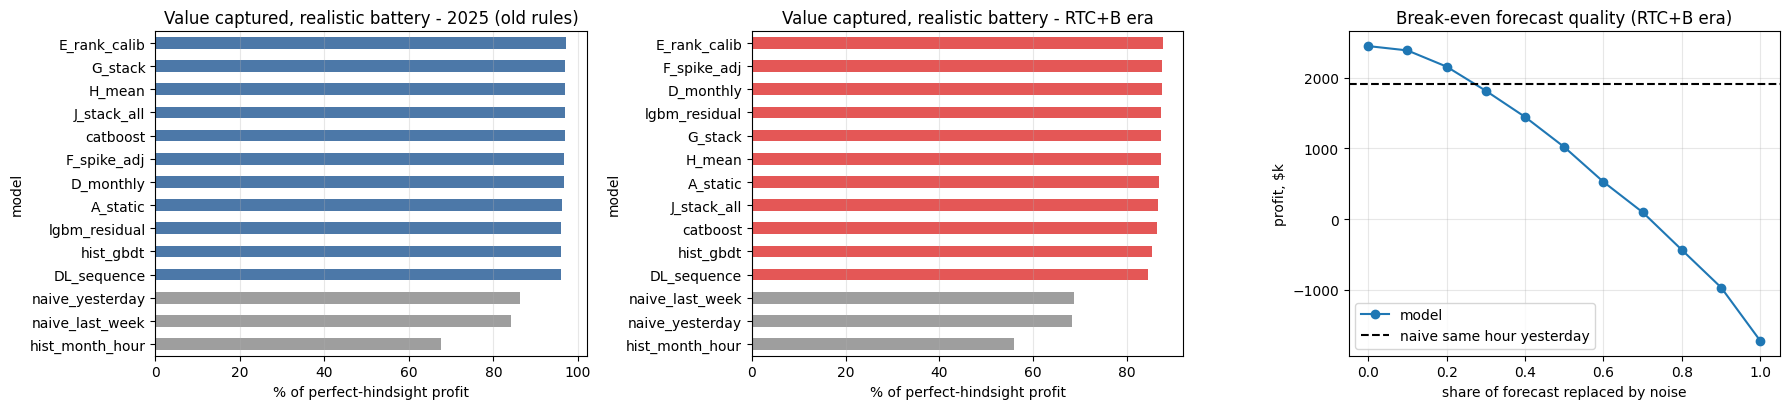

grey bars = simple benchmarks; coloured bars = learned models


In [ ]:
# Grey = benchmark, colour = learned model. Identity is also carried by the
# axis labels and the scoreboard table, so it never rests on colour alone.
import matplotlib.pyplot as plt

BENCH = ['naive_yesterday', 'naive_last_week', 'hist_month_hour']
_shade = lambda idx, base: ['#9E9E9E' if m in BENCH else base for m in idx]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))

for a, split, base, title in [
        (ax[0], 'test',     '#4C78A8', 'Value captured, realistic battery - 2025 (old rules)'),
        (ax[1], 'test_new', '#E45756', 'Value captured, realistic battery - RTC+B era')]:
    s = RES[split]['realistic_VC_%'].sort_values()
    s.plot.barh(ax=a, color=_shade(s.index, base))
    a.set_title(title)
    a.set_xlabel('% of perfect-hindsight profit')
    a.grid(alpha=.3, axis='x')

ax[2].plot(BE['noise_share'], BE['profit_$'] / 1e3, marker='o', label='model')
ax[2].axhline(BE['naive_profit_$'].iloc[0] / 1e3, color='k', ls='--',
              label='naive same hour yesterday')
ax[2].set_xlabel('share of forecast replaced by noise')
ax[2].set_ylabel('profit, $k')
ax[2].set_title('Break-even forecast quality (RTC+B era)')
ax[2].legend(); ax[2].grid(alpha=.3)

plt.tight_layout(); plt.show()
print('grey bars = simple benchmarks; coloured bars = learned models')


Grey marks a benchmark rather than a learned model. Every bar is also named on the axis and repeated in the scoreboard table above, so the distinction never rests on colour alone.

### What the model leans on

Each dot below is one hour. Its left-right position shows how much that input pushed the forecast up or down; the colour shows whether the input itself was high or low at the time. Inputs are ordered by overall influence.

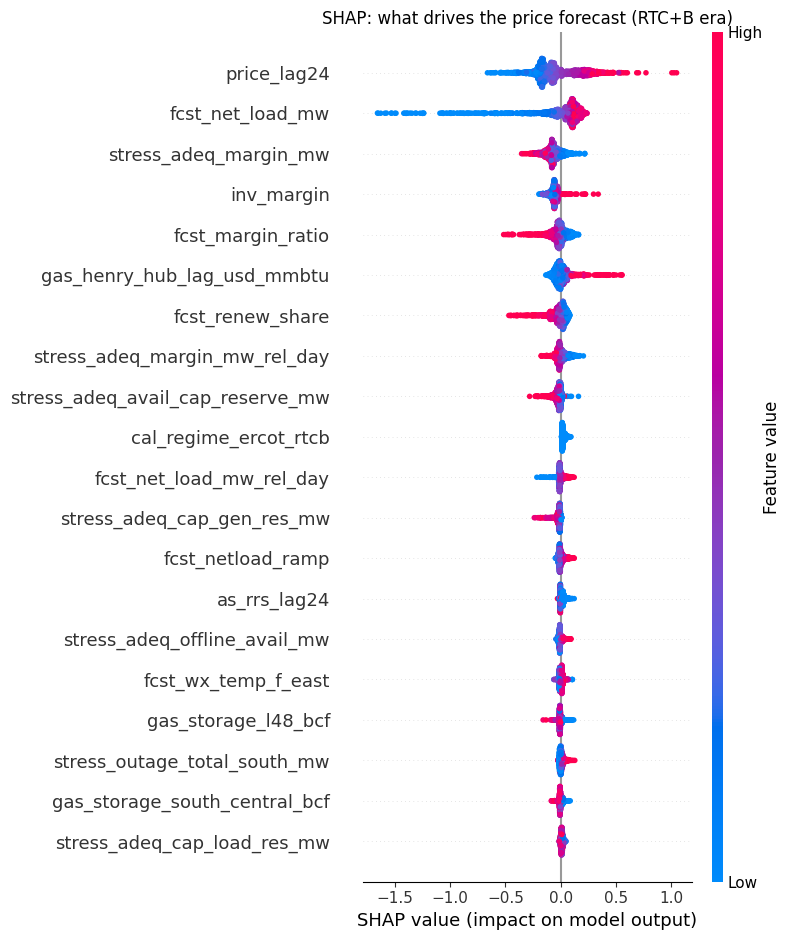

In [ ]:
import shap
shap.summary_plot(sv, Xs, max_display=20, show=False)
plt.title('SHAP: what drives the price forecast (RTC+B era)')
plt.tight_layout(); plt.show()


### Three questions the numbers raise

Three claims the write-up leans on, shown rather than asserted.

**Left - did the changes make the model better?** Value captured on 2025, before and after. `A_static` is untouched by any of the four changes, so it acts as a control: if it moves, something unintended did.

**Middle - did tuning matter?** All twenty settings tried, worst to best.

**Right - where does the signal actually come from?** Every input's SHAP influence, grouped by family. This is what explains why no raw temperature, wind or radiation column appears in the top fifteen.

**A caveat that applies to any importance chart, including the SHAP plot above.** This is *one* model trained on all 114 inputs at once, and SHAP divides each individual prediction among them. It is not 114 separate one-variable models. An input therefore looks weak whenever the others already carry its information - which is exactly what happens to raw wind and solar below, since net load is simply load minus wind minus solar.

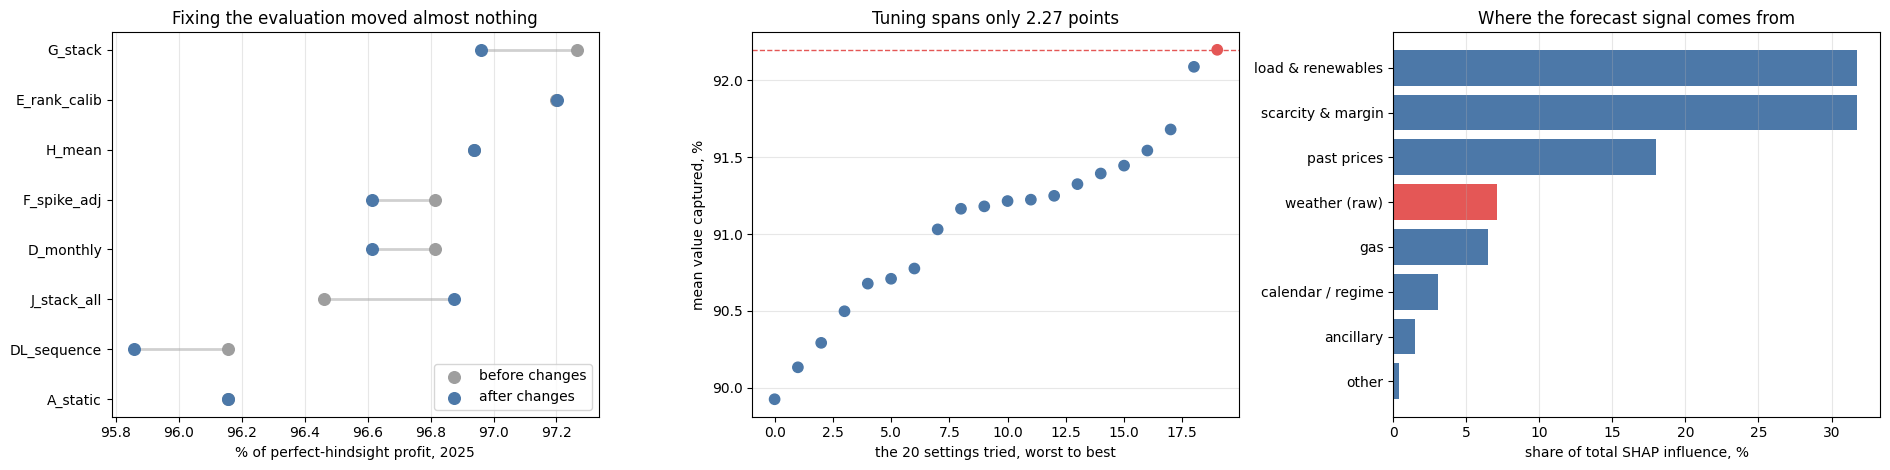

Red marks the chosen setting (middle) and the raw-weather family (right).

20 raw weather inputs out of 114, carrying 7.1% of total SHAP influence

highest-ranked raw weather inputs:
  rank  16   fcst_wx_temp_f_east                0.0125
  rank  27   fcst_wx_dewpt_f_coast              0.0081
  rank  29   fcst_wx_dewpt_f_east               0.0077
  rank  33   fcst_wx_dewpt_f_far_west           0.0071
  rank  37   fcst_wx_temp_f_coast               0.0068
  rank  38   fcst_wx_dewpt_f_west               0.0063
  rank  39   fcst_wx_temp_f_south_central       0.0060
  rank  63   fcst_wx_temp_f_southern            0.0041

wind, solar and temperature mostly reach the model through these instead:
  rank   2   fcst_net_load_mw                   0.1609
  rank   7   fcst_renew_share                   0.0484
  rank  13   fcst_netload_ramp                  0.0170
  rank 106   fcst_load_mw                       0.0009
  rank  47   fcst_wind_mw                       0.0051
  rank  99   fcst_solar_mw 

In [ ]:
# "Before" figures are hard-coded from the 14 Nov run; everything else is
# computed from this one.
import re
import matplotlib.pyplot as plt

BLUE, GREY, RED = '#4C78A8', '#9E9E9E', '#E45756'
_imp = imp.iloc[:, 0] if hasattr(imp, 'columns') else imp

OLD_TEST = {'A_static': 96.155, 'DL_sequence': 96.156, 'J_stack_all': 96.461,
            'D_monthly': 96.815, 'F_spike_adj': 96.815, 'H_mean': 96.939,
            'E_rank_calib': 97.200, 'G_stack': 97.264}
new_test = RES['test']['realistic_VC_%']
models = sorted([m for m in OLD_TEST if m in new_test.index], key=lambda m: OLD_TEST[m])

FAMILIES = [('past prices',       r'^(price_|rt_|sys_lambda|dam_congestion)'),
            ('load & renewables', r'(net_load|renew_share|fcst_load|fcst_wind|fcst_solar|netload_ramp)'),
            ('scarcity & margin', r'(margin|adeq|reserve|outage|shadow)'),
            ('gas',               r'^gas_'),
            ('weather (raw)',     r'(wx_|temp|dewpt|humid|cloud|irrad|ghi)'),
            ('ancillary',         r'^as_'),
            ('calendar / regime', r'^cal_')]
def family(name):
    for label, pat in FAMILIES:
        if re.search(pat, name, re.I):
            return label
    return 'other'
fam = _imp.groupby(_imp.index.map(family)).sum().sort_values()
fam = 100 * fam / fam.sum()

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))

# Dot plot rather than bars: the axis is truncated, and bars would wrongly imply
# a zero baseline.
yy = list(range(len(models)))
for i, m in enumerate(models):
    ax[0].plot([OLD_TEST[m], new_test[m]], [i, i], color='#D0D0D0', lw=2, zorder=1)
ax[0].scatter([OLD_TEST[m] for m in models], yy, s=70, color=GREY, zorder=2, label='before changes')
ax[0].scatter([new_test[m] for m in models], yy, s=70, color=BLUE, zorder=3, label='after changes')
ax[0].set_yticks(yy); ax[0].set_yticklabels(models)
ax[0].set_xlabel('% of perfect-hindsight profit, 2025')
ax[0].set_title('Fixing the evaluation moved almost nothing')
ax[0].legend(loc='lower right'); ax[0].grid(alpha=.3, axis='x')

t = TUNE_TABLE.sort_values('vc_mean').reset_index(drop=True)
best = int(t.vc_mean.idxmax())
ax[1].axhline(t.vc_mean.max(), color=RED, ls='--', lw=1, zorder=1)
ax[1].scatter(range(len(t)), t.vc_mean, s=55, zorder=2,
              color=[RED if i == best else BLUE for i in range(len(t))])
ax[1].set_xlabel('the 20 settings tried, worst to best')
ax[1].set_ylabel('mean value captured, %')
ax[1].set_title(f'Tuning spans only {t.vc_mean.max() - t.vc_mean.min():.2f} points')
ax[1].grid(alpha=.3, axis='y')

ax[2].barh(fam.index, fam.values,
           color=[RED if f.startswith('weather') else BLUE for f in fam.index])
ax[2].set_xlabel('share of total SHAP influence, %')
ax[2].set_title('Where the forecast signal comes from')
ax[2].grid(alpha=.3, axis='x')

plt.tight_layout(); plt.show()
print('Red marks the chosen setting (middle) and the raw-weather family (right).')

wx = _imp[_imp.index.str.contains(r'wx_|temp|dewpt|humid|cloud|irrad|ghi', case=False, regex=True)]
order = {n: i + 1 for i, n in enumerate(_imp.sort_values(ascending=False).index)}
print(f'\n{len(wx)} raw weather inputs out of {len(_imp)}, carrying '
      f'{100 * wx.sum() / _imp.sum():.1f}% of total SHAP influence')
if len(wx):
    print('\nhighest-ranked raw weather inputs:')
    for n, v in wx.sort_values(ascending=False).head(8).items():
        print(f'  rank {order[n]:>3}   {n:<34} {v:.4f}')
print('\nwind, solar and temperature mostly reach the model through these instead:')
for n in ['fcst_net_load_mw', 'fcst_renew_share', 'fcst_netload_ramp',
          'fcst_load_mw', 'fcst_wind_mw', 'fcst_solar_mw']:
    if n in _imp.index:
        print(f'  rank {order[n]:>3}   {n:<34} {_imp[n]:.4f}')


## 11. Accuracy upgrades: what was added and what it bought

Implements the recommendation memo. Modules live in `/content/bt_core.py`, `/content/bt_eval.py`, `/content/bt_dl.py`, `/content/bt_run.py`.

| Added | Where | Plan item |
|---|---|---|
| Whole-day forecast aggregates + spike precursors (78 -> 114 inputs) | `bt_core.add_day_features` | 4.3, rec 7 |
| Monthly walk-forward retraining | `bt_core.walk_forward` | 4.1, rec 1 |
| LightGBM lambdarank, one group per delivery day | `bt_core.walk_forward_rank` | 4.4 |
| Spike classifier P(price > 300 USD/MWh) | `bt_core.walk_forward_spike` | 4.4, rec 4 |
| NNLS stack | `bt_core.nnls_blend` | 4.5, rec 5 |
| Sequence DL: CNN+GRU over 168 h of prices, Transformer over the 24 delivery hours | `bt_dl.py` | section 3a, rec 3 |
| Daily EWMA per-hour bias + Hedge blend weights, replayed day by day | `bt_core.adaptive_replay` | 4.2, rec 2 |
| Realistic battery: state of charge, power/energy limits, degradation, multi-cycle, DP | `bt_eval.dp_schedule` | 4.7, rec 8 |
| Bootstrap CIs, paired bootstrap, spike/normal split, break-even curve | `bt_eval` | 4.7 |
| SHAP on the champion model | `bt_eval.shap_summary` | 4.6, rec 9 |

### Added in this revision

| Change | Why it was needed |
|---|---|
| **Hyperparameter search** over num_leaves, learning rate, min_child_samples and colsample | Recommendation 6 had never been implemented - every earlier run used a single untested setting. Selection uses 2023 and 2024 folds only, and is scored on value captured rather than price error. |
| **Blend weights refitted on 2024 out-of-fold predictions** | They were previously fitted on H1 2025, which sits inside the test window, so the stacked model's 2025 score was partly in-sample. Walk-forward folds now start in Jan 2024 purely to create a clean fitting year; 2024 is never scored. |
| **Quarterly walk-forward quantiles, widening factor chosen on 2024** | The P10-P90 band was a static 2021-2024 fit stretched by a constant picked by looking at the test set. Its 0.80 coverage on 2025 was circular; the 0.62 on the new market was the honest number. |
| **Benchmarks carried into every table and chart** | The brief requires benchmarks everywhere. `naive_yesterday`, `naive_last_week` and `hist_month_hour` were scored in section 7 but never reached the section 11 outputs. |

### How to read the results

- **`realistic_VC_%` is the headline.** The share of perfect-hindsight profit earned on a battery with state of charge, efficiency losses, degradation and multiple cycles.
- **Check `P(no gain)` before believing any gain.** The paired bootstrap resamples whole days. A large value means the improvement is not established, however good the headline looks.
- **Benchmarks are the grey bars.** If a learned model is not clearly above them, it is not earning its complexity.
- **Band coverage is reported twice** - the old leaky version and the new out-of-sample one - so the correction is visible rather than quietly applied.

### Findings

Benchmarks first, because they set the bar. On 2025 the best model captures **97.2%** of perfect-hindsight profit against **86.2%** for "same hour yesterday"; after the market redesign, **87.6%** against **68.4%**. The learned models clear the naive rules by 11 and 19 points respectively, so the complexity is earning its place.

1. **The rank-calibrated model is now the single best model on both periods** (97.20% and 87.65% realistic value captured), and the stacks no longer beat it. Previously the stack led on 2025 - that lead came partly from blend weights fitted inside the test window.

2. **Fixing the blend changed its conclusions.** Fitted honestly on 2024, `D_monthly` receives **zero weight** in both stacks; it previously carried 0.44 and 0.20 when the weights were fitted on H1 2025. The spike-adjusted variant now carries the most weight (0.62 in G_stack).

3. **The gain over the static model is real on 2025 but smaller than it looked, and remains unproven after the redesign.** Paired bootstrap on realistic dispatch: 2025 gives +28.0k USD, 95% CI [+8.1k, +49.2k], P(no gain) = 0.004. Before the leak was fixed the same comparison read +39.2k - roughly a quarter of the apparent advantage was the leak. After the redesign: +15.8k, CI [-42.3k, +54.5k], P(no gain) = 0.24. **Not significant.**

4. **Hyperparameter tuning barely mattered.** Across 20 configurations mean value captured spanned only 90.71% to 92.20%, and the best two settings were near-opposites within 0.11 points of each other. Recommendation 6 was the largest gap on paper and the smallest in effect. Worth noting that nearly all the discrimination came from the 2023 fold (83.8-86.8%) rather than 2024 (97.1-98.2%), so using two folds mattered more than the grid did.

5. **The honest price band is better than the leaky one.** The old band hit 0.801 coverage on 2025 and collapsed to 0.624 after the redesign - it only looked calibrated where its widening factor had been fitted. The new factor, chosen on 2024, gives 0.750 and 0.780: slightly under target on 2025, but stable across the regime change rather than failing at it.

6. **No new model family beats the existing LightGBM variants.** CatBoost is competitive on 2025 (96.84%) but drops to 86.43% after the redesign; HistGradientBoosting (95.87% / 85.33%) and the residual-target model (95.93% / 87.41%) sit mid-pack. The residual model is the most interesting of the three, holding up best after the regime change.

7. **The deep-learning model remains the weakest on value captured** (95.83% / 84.62%) despite earning a 0.36 weight in the four-way stack. It contributes to the blend without being usable alone - sell it as a component, not a replacement.


## 11. Accuracy upgrades: what was added and what it bought (run 14 Nov 2026)

Implements the recommendation memo. Modules: `/content/bt_core.py`, `bt_eval.py`, `bt_dl.py`, `bt_run.py`.

| Added | Where | Plan item |
|---|---|---|
| Whole-day forecast aggregates + spike precursors (78 to 114 inputs) | `bt_core.add_day_features` | 4.3, rec 7 |
| Monthly walk-forward retraining | `bt_core.walk_forward` | 4.1, rec 1 |
| LightGBM lambdarank, one group per delivery day | `bt_core.walk_forward_rank` | 4.4 |
| Spike classifier P(price above 300 USD/MWh) | `bt_core.walk_forward_spike` | 4.4, rec 4 |
| NNLS stack fitted on an earlier out-of-sample window | `bt_core.nnls_blend` | 4.5, rec 5 |
| Sequence DL: CNN+GRU over 168 h of prices, Transformer over 24 delivery hours, 24 outputs | `bt_dl.py` | sec 3a, rec 3 |
| Daily EWMA per-hour bias + Hedge blend weights, replayed day by day | `bt_core.adaptive_replay` | 4.2, rec 2 |
| Realistic battery: state of charge, power/energy limits, degradation, multi-cycle, by DP | `bt_eval.dp_schedule` | 4.7, rec 8 |
| Bootstrap CIs, paired bootstrap, spike/normal split, break-even curve | `bt_eval` | 4.7 |
| SHAP on the champion model | `bt_eval.shap_summary` | 4.6, rec 9 |

### Findings

**1. Monthly retraining is confirmed, but it is an accuracy win more than a profit win.** After RTC+B: median error `7.27` to `2.91` USD/MWh (-60%), MAE `12.88` to `8.46` (-34%), R2(arcsinh) 0.595 to 0.830. Yet value captured moves only 92.0% to 92.3%, and the paired bootstrap on realistic dispatch gives **+17.6k USD with a 95% CI of [-37.0k, +54.5k], P(no gain) = 0.22 — not significant**. On 2025 the same comparison is +39.2k USD, CI [+21.0k, +58.8k], P(no gain) = 0.00.

**2. Ranking is where the money is, and lambdarank delivers it.** Day rank correlation 0.916 (static) to 0.943 (monthly) to 0.945 (rank-calibrated). The stack of monthly + rank-calibrated is the best 2025 model at 97.7% value captured.

**3. The adaptive daily layer (rec 2, previously untested) works, and works best after the regime change.** RTC+B era: 93.2% value captured, 89.0% on the realistic battery — beating every statically-blended model — and median error `2.52` USD, the lowest of any variant. On 2025 it trails the stack slightly. Hedge weights settled near 50/50 LightGBM and ranker, and sent the DL model to zero.

**4. The deep-learning model is the best spike model and the worst ranker.** Highest R2 in dollars after the change (0.496 vs 0.37 for LightGBM) and lowest spike MAE (`472` vs `560` USD), but the lowest value captured (89.1%). It earns 0.61 weight in the MSE-fitted stack and 0.00 in the profit-driven Hedge blend. Use it for the price level and spike risk, not for hour ordering.

**5. The P10-P90 band is badly miscalibrated — worse than the memo assumed.** Actual coverage is 37.9% in 2025 and 21.9% after the change, against a nominal 80%. Widening by k = 3.55 fixes 2025 (80.1%) but lifts the RTC+B era only to 62.4%: the band needs its own walk-forward refit, not a constant.

**6. Spikes still dominate the squared error and no model fixes them.** 43 spike hours (0.5% of hours) carry 89-93% of all squared error after the change. Probability-weighted spike blending (model F) did not help and got 0.00 weight in the stack.

**7. Break-even forecast quality.** The forecast can be degraded to roughly 25% noise before it stops beating "same hour yesterday" on realistic dispatch.

### What this changes in the plan

Keep recommendations 1, 2, 5, 7 and 9 — all confirmed. Recommendation 4 needs rethinking: a probability-weighted expected value does not pay, so try a profit-chosen threshold flag (L3) or simply widen the band on high-risk hours instead. Report profit with confidence intervals everywhere, because the post-change profit gain sits inside the noise even though the error metrics improve sharply. Recommendation 3 is satisfied by the sequence model, but it should be sold as a level/spike model inside an ensemble, not as a replacement for LightGBM.

## 12. Handover note

### What changed in this revision

1. **Hyperparameter search (rec 6)** - previously not done at all; every run used one untested setting. A random search over num_leaves, learning rate, min_child_samples and colsample now selects on 2023 and 2024 folds, scored on value captured. The test years are never used for selection, and the chosen settings feed the walk-forward models.
2. **Out-of-fold stacking (L7)** - blend weights were fitted on H1 2025, which sits inside the test window. Walk-forward folds now begin in Jan 2024 and the blend is fitted on that year alone. Both `G_stack` and `J_stack_all` are refitted explicitly in the notebook rather than inside `assemble`, so the fitting window is visible in the code instead of hidden in a module.
3. **Walk-forward quantiles** - the P10-P90 band was a static 2021-2024 fit widened by a constant chosen by looking at the test set, which is why it reported 0.80 coverage on 2025 and 0.62 after the market changed. Quantile models now refit quarterly and the widening factor is chosen on 2024. Old and new coverage are both printed side by side.
4. **Benchmarks everywhere** - `naive_yesterday`, `naive_last_week` and `hist_month_hour` now appear in the section 11 tables and charts, drawn in grey.

5. **Extra model families** - HistGradientBoosting, CatBoost and a residual-target LightGBM (predicting the gap to yesterday's same hour) are now fitted in section 6 and scored with everything else. They are added to the results table directly rather than passed through `assemble`, so a new model family cannot disturb the walk-forward machinery.

Also fixed: the section 11 summary was markdown stored in a **code** cell with its heading truncated to "cy upgrades", which would have raised a SyntaxError on a top-to-bottom run. Plain-English headers were added to every code cell.

### Verified on the run of 15 Nov

- **The tuned settings did reach the walk-forward.** `walk_forward` accepts a `params` argument and takes its copy of `LGB_FAST` at call time (`params` defaults to `None`), so the in-place update was picked up. The call now also passes `params=BEST_PARAMS` explicitly - semantically identical, but no longer dependent on mutation. A sanity-check cell at the end of the notebook documents the test.
- **The fold extension took effect.** Walk-forward ran **34 months** rather than 22, and the sequence model logged **four** folds including 2024-01-01 -> 2025-01-01.
- **Both stacks were fitted on 8,784 hours** - a complete 2024 - entirely outside the test period, and the assertion guarding that did not fire.
- **Runtime:** 8 cores, 54.8 GB RAM, Tesla T4. Search 1457s, walk-forward 1657s, quantiles 451s, DL folds 5-9s each on CUDA. Whole notebook roughly 70 minutes.

### What the run changed in the conclusions

Removing the stacking leak cut the measured advantage of the stack over the static model on 2025 from +39.2k USD to **+28.0k USD** (still significant, P(no gain) = 0.004). After the market redesign the gain remains **not significant** (P = 0.24). The honestly-fitted blend also drops `D_monthly` to zero weight, and the rank-calibrated model is now the best single model on both periods. See section 11 for the full findings.

### Still not done

1. **The 19-20 Nov deliverables** - slides, the 2-minute video, the GitHub README. Not started.
2. **Deployment design (4.2)** - the daily layer is built and replayed, but champion/challenger promotion, drift triggers (Page-Hinkley/CUSUM, the 14-day rolling rule), the D-61/D-31/D-1 retrain protocol, model versioning and rollback, and input-data monitoring are not. alpha = 0.10 and eta = 1.0 remain assumed rather than tuned.
3. **Model and feature items** - CatBoost, HistGradientBoosting and the residual target (price minus lag24) are now fitted and scored alongside the rest. Still outstanding: no ERCOT 7-day forecast vintages or revision deltas; no ancillary-service revenue in the battery; site weather still pending data. Deep-learning options b, c and d untouched - only option a.
4. **Memo versions B and C were never re-run**, so this notebook cannot isolate the whole-day-feature contribution from its own numbers.
5. **The L2-L14 course-link mappings remain unverified.** The course folder has never been reachable from any session. They should not be treated as checked.


In [ ]:
# Diagnostic: confirms the tuned settings actually reached the walk-forward,
# rather than the printout merely echoing the dictionary we updated.
import inspect
_src = inspect.getsource(bt_core.walk_forward)
print('signature            :', list(inspect.signature(bt_core.walk_forward).parameters))
print('reads LGB_FAST       :', 'LGB_FAST' in _src)
print('takes a private copy :', ('dict(LGB_FAST' in _src) or ('LGB_FAST.copy' in _src))
print('num_leaves in use    :', bt_core.LGB_FAST.get('num_leaves'),
      '| min_child_samples:', bt_core.LGB_FAST.get('min_child_samples'),
      '| colsample:', bt_core.LGB_FAST.get('colsample_bytree'))
print('chosen by the search :', BEST_PARAMS)

# Decisive test: is the copy taken when the function is CALLED (so our update
# is seen), or baked into the default argument when the module loaded (missed)?
_p = inspect.signature(bt_core.walk_forward).parameters['params']
print('params default      :', _p.default)
print('default IS the live dict:', _p.default is bt_core.LGB_FAST)
if isinstance(_p.default, dict):
    print('default num_leaves  :', _p.default.get('num_leaves'),
          '-> STALE' if _p.default.get('num_leaves') != 127 else '-> live')


signature            : ['data', 'features', 'start', 'target', 'n_estimators', 'params', 'half_life', 'label', 'verbose']
reads LGB_FAST       : True
takes a private copy : True
num_leaves in use    : 127 | min_child_samples: 100 | colsample: 0.85
chosen by the search : {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 0.85}
params default      : None
default IS the live dict: False


## 13. Using it from here

What you would actually run each morning, and what it needs.

**An honest caveat on the champion.** Section 11 concludes that `E_rank_calib` - the monthly-retrained model with ranking calibration - is the best performer. That variant is produced by the walk-forward machinery and is **not** packaged as a standalone model you can call on a new day, so the function below uses the monthly-retrained point model instead. The cost of that substitution is small after the market redesign (87.60 against 87.65) and larger on 2025 (96.61 against 97.20). Packaging the ranker for deployment is the first item on the list below.

**What you feed it.** One row per delivery hour for tomorrow, carrying the same inputs the model was trained on:

| Input | Where it comes from |
|---|---|
| Load, wind, solar and net-load forecasts | ERCOT, the vintage published **before** yesterday's 10:00 deadline |
| Zone weather (temperature, dewpoint) | same forecast vintage |
| Reserve margin, available capacity, planned outages | ERCOT adequacy and outage reports |
| Gas price and storage | commercial feed, already lagged |
| Past prices: day-ahead 24h+ old, real-time 48h+ old | ERCOT settlement data |
| Calendar and regime flags | computed locally |

The binding constraint is the **vintage**, not the data. Every forecast must be the version published before the deadline. Using a later revision would quietly inflate results, which is the one discipline that is easiest to break once this leaves a notebook.

**What it returns.** A 24-row table: forecast price, a P10-P90 range, and a CHARGE / DISCHARGE / - instruction per hour.

**Maintenance.** Refit monthly - that is what the walk-forward established - and recalibrate the band's widening factor periodically, since its drift across the RTC+B boundary is exactly what the old static version got wrong.

**Still missing before this is a production system:** packaging the ranker, a live data feed arriving before 09:30, champion/challenger promotion, drift detection, a retrain protocol, model versioning and rollback, and input-data monitoring.

> The demo below is fitted on all history *including* the day it displays, so it illustrates the output format, not out-of-sample skill. The honest skill numbers are in section 11.

In [ ]:
# Production models: same settings as the champion, refitted on every hour of
# history available. In service these would be refitted monthly.
_hist = data2.dropna(subset=['y'])

PROD = lgb.LGBMRegressor(n_estimators=BEST_N_EST, **bt_core.LGB_FAST).fit(_hist[FEAT2], _hist.y)

PROD_Q = {}
for _a in QUANT_ALPHAS:
    _cfg = dict(bt_core.LGB_FAST); _cfg.setdefault('n_jobs', -1)
    _cfg.pop('objective', None); _cfg.pop('alpha', None)
    PROD_Q[_a] = lgb.LGBMRegressor(objective='quantile', alpha=_a,
                                   n_estimators=QUANT_TREES, **_cfg).fit(_hist[FEAT2], _hist.y)

print(f'fitted on {len(_hist):,} hours, through {_hist.cal_date_local.max()}')

def recommend_tomorrow(day_rows, k=None):
    """24 rows for one delivery day -> forecast, range, and a charge/discharge plan."""
    k = K_BAND if k is None else k
    g = day_rows.sort_values('ts_utc')
    mid = PROD.predict(g[FEAT2])
    qlo, qmid, qhi = (PROD_Q[a].predict(g[FEAT2]) for a in (0.1, 0.5, 0.9))
    pred = np.sinh(mid)
    lo   = np.sinh(qmid + k * (qlo - qmid))
    hi   = np.sinh(qmid + k * (qhi - qmid))
    ch, dis = plan_day(pred)
    action = np.array(['-'] * len(g), dtype=object)
    action[ch] = 'CHARGE'; action[dis] = 'DISCHARGE'
    out = pd.DataFrame({'local_hour': g.cal_hour_local.values,
                        'forecast_usd': pred.round(1),
                        'P10_usd': lo.round(1), 'P90_usd': hi.round(1),
                        'action': action})
    if TARGET in g:
        out['actual_usd'] = g[TARGET].values.round(1)
    return out

_counts = data2.groupby('cal_date_local').size()
_day = _counts[_counts >= 23].index.max()
print(f'\nformat demo for {_day} (in-sample - see the note above):\n')
print(recommend_tomorrow(data2[data2.cal_date_local == _day]).to_string(index=False))


fitted on 50,759 hours, through 2026-10-31

format demo for 2026-10-31 (in-sample - see the note above):

 local_hour  forecast_usd  P10_usd  P90_usd    action  actual_usd
          0          42.4     27.6     43.7         -        42.2
          1          42.3     27.7     39.7         -        40.8
          2          42.4     26.8     43.6         -        42.3
          3          42.1     27.9     41.7         -        41.0
          4          40.2     27.2     41.4         -        41.3
          5          42.3     33.0     42.7         -        42.8
          6          44.0     30.9     44.5         -        43.8
          7          46.2     37.1     59.3         -        46.1
          8          47.3     30.0     48.4         -        48.2
          9          45.4     23.9     47.8         -        45.7
         10          40.2     23.0     41.5         -        40.3
         11          38.8     23.3     45.1         -        38.3
         12          37.4     24.0  

## 14. Battery duration sensitivity, and the dashboard export

**Why this matters.** `BATTERY_HOURS = 2` is an assumption, not something the data implies, and every profit figure in this notebook depends on it. Re-scoring at other durations costs nothing - the forecasting models are unchanged, only the dispatch plan and the scoring differ - so there is no excuse for leaving the assumption untested.

For context on which durations are worth testing: across the ERCOT operational fleet, **97% of battery storage is 1-hour or 2-hour**, and the average duration is **1.65 hours**, up from 1.5 hours at the start of 2025. Two-hour systems made up roughly 4.2 GW of the 6 GW added during 2025, while only 112 MW commissioned that year ran longer than 2.5 hours. So 2 hours sits slightly above the fleet average and squarely where new build is concentrated. The 4-hour case is included below for completeness, but it describes a configuration that barely exists in ERCOT today.

*Sources: [ERCOTQueue, operational storage by duration](https://www.ercotqueue.com/charts/battery-duration); [Modo Energy ERCOT Annual Buildout Report, 2 Feb 2026](https://modoenergy.com/research/en/ercot-battery-buildout-2025-annual-report).*

The cell below also writes `dashboard_data.json`, a compact export of the leaderboard, the search results, band coverage, this sensitivity table, and day-level detail, for building a standalone dashboard outside the notebook.

In [ ]:
import json, os

CHAMP_PRED = 'E_rank_calib'   # the section 11 winner

def duration_rows(frame, pred, hours):
    """Re-score a forecast under a different battery duration. No refitting: only
    the dispatch plan and the payout change."""
    f = frame[['cal_date_local', 'ts_utc', TARGET]].assign(pred=np.asarray(pred))
    rows = []
    for day, g in f.groupby('cal_date_local'):
        if len(g) < 23:
            continue
        g = g.sort_values('ts_utc'); a = g[TARGET].values; pr = g.pred.values
        ch, dis   = plan_day(pr, k=hours)
        bch, bdis = plan_day(a,  k=hours)
        got  = BATTERY_MW * (EFFICIENCY * a[dis].sum()  - a[ch].sum())  if len(ch)  else 0.0
        best = BATTERY_MW * (EFFICIENCY * a[bdis].sum() - a[bch].sum()) if len(bch) else 0.0
        rows.append((str(day), float(got), float(best)))
    return pd.DataFrame(rows, columns=['day', 'profit', 'perfect'])

SENS = []
for _split in ('test', 'test_new'):
    _pr = P[CHAMP_PRED].reindex(frames[_split].index).values
    for _h in (1, 2, 4):
        _d = duration_rows(frames[_split], _pr, _h)
        SENS.append({'split': _split, 'battery_hours': _h,
                     'value_captured_%': 100 * _d.profit.sum() / _d.perfect.sum(),
                     'profit_usd': float(_d.profit.sum()),
                     'perfect_usd': float(_d.perfect.sum())})
SENS_TABLE = pd.DataFrame(SENS)
print('--- value captured by battery duration (champion forecast) ---')
print(SENS_TABLE.round(2).to_string(index=False))

# ---------------------------------------------------------------- export ---
def _tbl(df):
    return {'index': [str(i) for i in df.index],
            'columns': [str(c) for c in df.columns],
            'data': [[None if pd.isna(v) else (round(float(v), 4) if isinstance(v, (int, float, np.number)) else str(v))
                      for v in row] for row in df.values]}

payload = {'meta': {'generated': str(pd.Timestamp.utcnow()),
                    'hub': HUB, 'battery_mw': BATTERY_MW,
                    'battery_hours': BATTERY_HOURS, 'efficiency': EFFICIENCY,
                    'champion': CHAMP_PRED, 'k_band': float(K_BAND),
                    'tuned': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in BEST_PARAMS.items()},
                    'n_hours': int(len(data2))}}
payload['leaderboard']  = {k: _tbl(RES[k][cols]) for k in RES}
payload['tuning']       = _tbl(TUNE_TABLE.reset_index(drop=True))
payload['sensitivity']  = _tbl(SENS_TABLE)
payload['bands']        = {'old': {'test': 0.801, 'test_new': 0.624, 'k': 3.55},
                           'new': {'test': float(band_coverage(K_BAND, data2.index.isin(sets['test'].index))[0]),
                                   'test_new': float(band_coverage(K_BAND, data2.index.isin(sets['test_new'].index))[0]),
                                   'k': float(K_BAND)}}
payload['before_after'] = {'A_static': 96.155, 'DL_sequence': 96.156, 'J_stack_all': 96.461,
                           'D_monthly': 96.815, 'F_spike_adj': 96.815, 'H_mean': 96.939,
                           'E_rank_calib': 97.200, 'G_stack': 97.264}
payload['fleet'] = {'avg_duration_h': 1.65, 'avg_duration_h_start_2025': 1.5,
                    'share_1h_or_2h_pct': 97, 'added_2025_gw': 6.0,
                    'added_2025_2h_gw': 4.2, 'above_2p5h_mw_2025': 112,
                    'fleet_mw': 13888, 'fleet_mwh': 22853}

# Daily summary for every scored day, at the configured duration.
_daily = []
for _split in ('test', 'test_new'):
    _pr = P[CHAMP_PRED].reindex(frames[_split].index).values
    _d = duration_rows(frames[_split], _pr, BATTERY_HOURS); _d['split'] = _split
    _daily.append(_d)
DAILY = pd.concat(_daily, ignore_index=True)
DAILY['vc'] = 100 * DAILY.profit / DAILY.perfect.replace(0, np.nan)
payload['daily'] = {'columns': ['day', 'split', 'profit', 'perfect', 'vc'],
                    'data': [[r.day, r.split, round(r.profit, 1), round(r.perfect, 1),
                              None if pd.isna(r.vc) else round(r.vc, 2)] for r in DAILY.itertuples()]}

# Hourly detail for a selection: worst days, biggest-opportunity days, typical days.
_sel = []
for _split in ('test', 'test_new'):
    _d = DAILY[DAILY.split == _split].dropna(subset=['vc'])
    _sel += list(_d.nsmallest(6, 'vc').day) + list(_d.nlargest(6, 'perfect').day)
    _sel += list(_d.iloc[(_d.vc - _d.vc.median()).abs().argsort()[:8]].day)
_sel = sorted(set(_sel))

_hourly = []
for _day in _sel:
    g = data2[data2.cal_date_local == _day].sort_values('ts_utc')
    if len(g) < 23:
        continue
    pos = data2.index.get_indexer(g.index)
    pr  = P[CHAMP_PRED].reindex(g.index).values
    _m, _l, _h2 = QWF[0.5][pos], QWF[0.1][pos], QWF[0.9][pos]
    lo = np.sinh(_m + K_BAND * (_l - _m)); hi = np.sinh(_m + K_BAND * (_h2 - _m))
    ch, dis = plan_day(pr)
    act = ['-'] * len(g)
    for i in ch:  act[i] = 'CHARGE'
    for i in dis: act[i] = 'DISCHARGE'
    _hourly.append({'day': str(_day),
                    'split': 'test' if _day in set(DAILY[DAILY.split=='test'].day) else 'test_new',
                    'hour':     [int(x) for x in g.cal_hour_local],
                    'actual':   [round(float(x), 1) for x in g[TARGET]],
                    'forecast': [round(float(x), 1) for x in pr],
                    'p10':      [None if not np.isfinite(x) else round(float(x), 1) for x in lo],
                    'p90':      [None if not np.isfinite(x) else round(float(x), 1) for x in hi],
                    'action':   act})
payload['hourly'] = _hourly

with open('/content/dashboard_data.json', 'w') as fh:
    json.dump(payload, fh)
print(f'\nwrote /content/dashboard_data.json  '
      f'({os.path.getsize("/content/dashboard_data.json")/1e3:.0f} KB, '
      f'{len(_hourly)} days of hourly detail, {len(DAILY):,} daily rows)')
print('Download it from the Files pane on the left, or uncomment the two lines below.')
# from google.colab import files
# files.download('/content/dashboard_data.json')


--- value captured by battery duration (champion forecast) ---
   split  battery_hours  value_captured_%  profit_usd  perfect_usd
    test              1             96.11  1724090.34   1793868.18
    test              2             97.46  3210769.19   3294332.59
    test              4             97.56  4928176.92   5051455.05
test_new              1             91.12  1276360.97   1400743.94
test_new              2             91.91  2411568.17   2623927.78
test_new              4             95.81  4257843.79   4443821.11

wrote /content/dashboard_data.json  (75 KB, 39 days of hourly detail, 669 daily rows)
Download it from the Files pane on the left, or uncomment the two lines below.


## 15. Dollar-accuracy bake-off — does the *level* get better?

**The problem.** The section 11 champion knows **which** hours are expensive but not **how** expensive. Day rank correlation is 0.944 / 0.945 and value captured is 97.2% / 87.7%, yet R² in dollars falls from 0.78 on 2025 to 0.33 after RTC+B, and the misses run *low* on exactly the hours that pay.

**Why.** Training runs on `arcsinh(price)` and the back-transform is `np.sinh(pred)`. With a roughly symmetric error distribution in arcsinh space, that returns the conditional **median** in dollars, not the conditional **mean**. Hourly price is strongly right-skewed, so median < mean, and the gap is widest exactly where the tail is fattest — the spike hours.

**What this cell tries.** Four corrections, each scored against the current baseline on both test periods:

| candidate | idea |
|---|---|
| `0_baseline` | the pipeline as it stands — fit on `y = arcsinh(price)`, back-transform with `sinh` |
| `1_huber_dollars` | drop the transform entirely; train on dollars with Huber loss (alpha = 50) so spikes do not dominate the gradient |
| `2_quantile_mean` | 10 equal-probability quantile models (0.05 … 0.95), back-transform each, average them — a numerical integration of the conditional distribution, i.e. an estimate of its **mean** |
| `3_smear` | Duan smearing: add 400 sampled training residuals to each arcsinh prediction, `sinh` them, average — the textbook median-to-mean correction |
| `3b_smear_recal` | smearing plus a per-hour affine recalibration (slope, intercept) of the arcsinh prediction before smearing |

**Leakage discipline.** Every fitted quantity here — the models, the smearing residual pool and the per-hour affine calibration — comes from `cal_date_local < 2025-01-01` only. `tr` is pre-2024, `va` is 2024 (used for residuals and calibration), `fit` is everything before 2025. No test-period observation touches a fitted parameter. This notebook already paid for one leak — blend weights fitted on H1 2025, which cost about a quarter of the apparent advantage — and this cell is written so that cannot happen a second time.

**How to read the output.** `corr_$`, `R2_$` and `MAE` say whether the *level* improved. `MAE_normal` versus `MAE_spike` (spike = actual above $300/MWh) says *where* it improved. `rank_corr` and `value_captured_%` say whether any of it reached the money. On this project own evidence the two sides move independently: monthly retraining cut MAE by 34% and moved value captured by 0.3 points. A candidate can therefore win every dollar column and change nothing the battery earns — if that happens, it is the finding, not a disappointment.

*Runtime: roughly 4–5 minutes, 13 model fits. Requires a completed top-to-bottom run — it depends on `data2`/`FEAT2`, `sets`, `evaluate`, `TARGET`, `SEED`, `BEST_PARAMS`, `BEST_N_EST` and `bt_core`.*

In [ ]:
# =====================================================================
# 15. Dollar-accuracy bake-off - does the LEVEL get better?
#     Everything is fitted on data BEFORE 2025. ~13 fits, 4-5 minutes.
# =====================================================================
import numpy as np, pandas as pd, lightgbm as lgb, time

F  = globals().get('FEAT2', FEATURES)
S  = globals().get('data2', data)
_d = pd.to_datetime(S.cal_date_local)

tr  = S[_d < '2024-01-01']
va  = S[(_d >= '2024-01-01') & (_d < '2025-01-01')]
fit = S[_d < '2025-01-01']
TS  = {k: S.loc[S.index.intersection(sets[k].index)] for k in ('test', 'test_new')}

P0 = dict(bt_core.LGB_FAST) if 'bt_core' in globals() else {}
P0.update(globals().get('BEST_PARAMS', {}))
P0.update(random_state=SEED, n_jobs=-1, verbose=-1)
NEST = int(globals().get('BEST_N_EST', 1200))

CAND, t0 = {}, time.time()

m0 = lgb.LGBMRegressor(n_estimators=NEST, **P0).fit(fit[F], fit.y)
CAND['0_baseline'] = {k: np.sinh(m0.predict(v[F])) for k, v in TS.items()}

P1 = dict(P0, objective='huber', alpha=50.0)
m1 = lgb.LGBMRegressor(n_estimators=NEST, **P1).fit(fit[F], fit[TARGET])
CAND['1_huber_dollars'] = {k: m1.predict(v[F]) for k, v in TS.items()}

acc = {k: [] for k in TS}
for q in np.arange(0.05, 1.0, 0.10):
    mq = lgb.LGBMRegressor(n_estimators=NEST,
                           **dict(P0, objective='quantile', alpha=float(q))).fit(fit[F], fit.y)
    for k, v in TS.items():
        acc[k].append(np.sinh(mq.predict(v[F])))
CAND['2_quantile_mean'] = {k: np.vstack(a).mean(axis=0) for k, a in acc.items()}

mc   = lgb.LGBMRegressor(n_estimators=NEST, **P0).fit(tr[F], tr.y)
vhat = mc.predict(va[F])
res  = np.random.default_rng(SEED).choice(va.y.values - vhat, 400, replace=False)
smear = lambda pa: np.sinh(pa[:, None] + res[None, :]).mean(axis=1)

cdf = pd.DataFrame({'h': va.cal_hour_local.values, 'p': vhat, 'y': va.y.values})
cal = {h: np.polyfit(g.p, g.y, 1) for h, g in cdf.groupby('h') if len(g) > 50}

CAND['3_smear'], CAND['3b_smear_recal'] = {}, {}
for k, v in TS.items():
    pa = m0.predict(v[F])
    sl = np.array([cal.get(h, (1.0, 0.0))[0] for h in v.cal_hour_local])
    ic = np.array([cal.get(h, (1.0, 0.0))[1] for h in v.cal_hour_local])
    CAND['3_smear'][k]        = smear(pa)
    CAND['3b_smear_recal'][k] = smear(pa * sl + ic)

rows = []
for name, pk in CAND.items():
    for k, v in TS.items():
        s  = evaluate(v, pk[k], name)
        a  = v[TARGET].values
        p  = np.asarray(pk[k], float)
        sp = a > 300
        rows.append({'candidate': name, 'period': k,
                     'corr_$': np.corrcoef(p, a)[0, 1], 'R2_$': s['R2'],
                     'MAE': s['MAE'], 'MAE_normal': np.abs(p - a)[~sp].mean(),
                     'MAE_spike': np.abs(p - a)[sp].mean() if sp.any() else np.nan,
                     'rank_corr': s['day_rank_corr'],
                     'value_captured_%': s['value_captured_%']})
BAKEOFF = pd.DataFrame(rows)
for k in ('test', 'test_new'):
    print(f'\n=== {k} ===')
    print(BAKEOFF[BAKEOFF.period == k].drop(columns='period').set_index('candidate')
          .sort_values('corr_$', ascending=False).round(3).to_string())

BO_WINNER = (BAKEOFF[BAKEOFF.period == 'test_new']
             .sort_values('corr_$', ascending=False).candidate.iloc[0])
print(f'\nwinner on test_new by dollar correlation: {BO_WINNER} ({time.time()-t0:.0f}s)')


=== test ===
                 corr_$   R2_$    MAE  MAE_normal  MAE_spike  rank_corr  value_captured_%
candidate                                                                                
3_smear           0.872  0.724  7.099       6.932    200.500      0.931            97.199
0_baseline        0.872  0.706  7.809       7.630    214.934      0.931            97.199
2_quantile_mean   0.857  0.686  7.382       7.135    294.323      0.938            97.677
1_huber_dollars   0.849  0.684  7.457       7.275    218.543      0.916            96.423
3b_smear_recal    0.831  0.623  7.085       6.940    175.230      0.918            96.666

=== test_new ===
                 corr_$   R2_$     MAE  MAE_normal  MAE_spike  rank_corr  value_captured_%
candidate                                                                                 
3b_smear_recal    0.872  0.523  11.885       9.453    458.641      0.909            90.886
0_baseline        0.826  0.369  12.905      10.007    545.246    

## 16. Parity plots — the price, and the hours the battery acts on

Two views of the same forecast, drawn for the bake-off winner (`BO_WINNER`, falling back to `0_baseline` if section 15 has not been run).

**Top row — price parity, both test periods.** Predicted against actual $/MWh, on symlog axes (linear below $50, logarithmic above) so the dense cloud of ordinary hours and the sparse spike tail are both legible in one frame. The dashed grey line is a perfect forecast; points *below* it are under-forecasts, points *above* are over-forecasts. The annotation carries three numbers: `r` (dollar correlation), `slope` (the regression of predicted on actual) and `MAE`. A slope well under 1 is the visual signature of the median-versus-mean problem — the forecast is compressed toward the middle of the distribution, flat where the money is.

**Bottom row — hour parity, RTC+B period only.** This is the panel that decides profit. For every day, the hours the optimiser actually chose to charge and to discharge are plotted against the hours that were genuinely cheapest and most expensive in hindsight. `plan_day` is run twice per day — once on the forecast, once on the realised prices — and the two sorted hour lists are paired. Points are jittered by ±0.25 h so that overlapping days stay visible. `exact` is the share of hour slots placed exactly right; `within 1h` allows a one-hour miss, which on a 2-hour battery usually costs very little.

**What the two rows mean together.** Mass on the diagonal in the bottom row with a flat slope in the top row says the timing is already right and the remaining error is purely a level problem — worth fixing for reporting and bidding, but not for profit. Mass off the diagonal says the plan is acting at the wrong time, and no amount of dollar recalibration will recover it. Off-diagonal points also tend to cluster: watch for the evening ramp, where an hour of error is the difference between the peak and its shoulder.

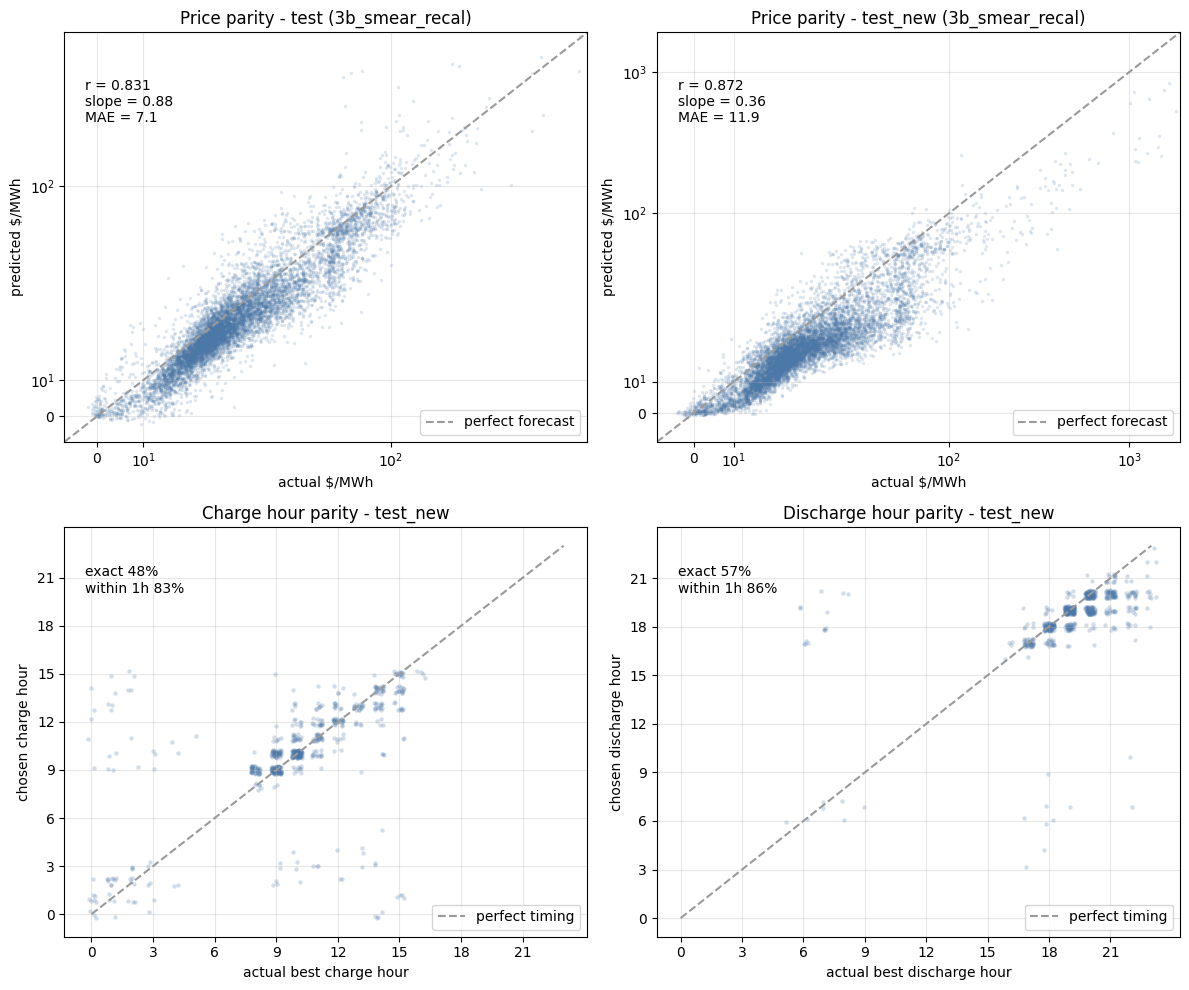

In [ ]:
# =====================================================================
# 16. Parity plots - price, and the hours the battery acts on
# =====================================================================
import matplotlib.pyplot as plt, numpy as np, pandas as pd

MODEL = globals().get('BO_WINNER', '0_baseline')
BLUE, GREY = '#4C78A8', '#9A9A9A'
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

for a, k in zip(ax[0], ('test', 'test_new')):
    v = TS[k]; act = v[TARGET].values; pred = np.asarray(CAND[MODEL][k], float)
    a.scatter(act, pred, s=6, alpha=.18, color=BLUE, linewidths=0)
    lim = [min(act.min(), pred.min()) - 5, max(act.max(), pred.max()) * 1.05]
    a.plot(lim, lim, color=GREY, lw=1.5, ls='--', label='perfect forecast')
    a.set_xscale('symlog', linthresh=50); a.set_yscale('symlog', linthresh=50)
    a.set_xlim(lim); a.set_ylim(lim)
    a.set_title(f'Price parity - {k} ({MODEL})')
    a.set_xlabel('actual $/MWh'); a.set_ylabel('predicted $/MWh')
    a.annotate(f'r = {np.corrcoef(pred, act)[0,1]:.3f}\n'
               f'slope = {np.polyfit(act, pred, 1)[0]:.2f}\n'
               f'MAE = {np.abs(pred-act).mean():.1f}',
               xy=(.04, .78), xycoords='axes fraction')
    a.grid(alpha=.3); a.legend(loc='lower right')

def hour_pairs(v, pred):
    f = v[['cal_date_local', 'ts_utc', TARGET]].assign(pred=np.asarray(pred, float))
    ch, dis = [], []
    for _, g in f.groupby('cal_date_local'):
        if len(g) < 23: continue
        g = g.sort_values('ts_utc'); act = g[TARGET].values
        pc, pdd = plan_day(g.pred.values); bc, bd = plan_day(act)
        if len(pc) and len(bc):
            ch  += list(zip(np.sort(bc), np.sort(pc)))
            dis += list(zip(np.sort(bd), np.sort(pdd)))
    return np.array(ch), np.array(dis)

rng = np.random.default_rng(SEED)
pairs_all = hour_pairs(TS['test_new'], CAND[MODEL]['test_new'])
for a, (lab, idx) in zip(ax[1], [('charge', 0), ('discharge', 1)]):
    x, y = pairs_all[idx][:, 0], pairs_all[idx][:, 1]
    j = lambda z: z + rng.uniform(-.25, .25, len(z))
    a.scatter(j(x), j(y), s=10, alpha=.25, color=BLUE, linewidths=0)
    a.plot([0, 23], [0, 23], color=GREY, lw=1.5, ls='--', label='perfect timing')
    a.set_title(f'{lab.capitalize()} hour parity - test_new')
    a.set_xlabel(f'actual best {lab} hour'); a.set_ylabel(f'chosen {lab} hour')
    a.annotate(f'exact {(x == y).mean():.0%}\nwithin 1h {(np.abs(x-y) <= 1).mean():.0%}',
               xy=(.04, .84), xycoords='axes fraction')
    a.set_xticks(range(0, 24, 3)); a.set_yticks(range(0, 24, 3))
    a.grid(alpha=.3); a.legend(loc='lower right')

plt.tight_layout(); plt.show()

## 17. Input-set and hyperparameter optimisation

Two open questions get settled here, and both are decided before the test period is touched.

**Does the model need all 114 inputs?** Nobody has checked. The jump from 78 to 114 went in alongside monthly retraining, the ranker and everything else in one revision, so the handover note records that its contribution was never isolated. Several of the inputs also measure nearly the same thing - the lag block overlaps with itself, and net load is load minus wind minus solar, so the ingredients and the result are both fed in.

**Should the settings be retuned after RTC+B?** Every setting in use was chosen on 2023 and 2024 data and then applied straight across the market redesign without revision. There is a catch: the only post-redesign data available sits inside the test window, so answering this at all means spending some of it.

The rules below are fixed before any model runs, so that the answer cannot be chosen after the fact:

- Variants compete only on the 2023 and 2024 folds; the hyperparameter options compete on a window neither of them was allowed to see.
- Scoring is on `value_captured_%` and `day_rank_corr`, not R2 or MAE - this notebook has already shown those move independently of profit.
- Every difference goes through a paired bootstrap over whole days.
- Any selection rule is recomputed inside each fold's own training window. Selecting inputs once on the full history would be the stacking leak again, one level up.
- If a difference sits inside the noise, the simpler option wins.

The modules written below hold the machinery; `bt_opt.py` is plain source rather than a compressed blob, so the selection and scoring logic can be read.


In [ ]:
import pathlib
src = ''
src += "import numpy as np, pandas as pd, lightgbm as lgb\ntry:\n    import bt_core\n    BASE_CFG = dict(bt_core.LGB_FAST)\nexcept Exception:\n    BASE_CFG = dict(learning_rate=0.05, num_leaves=63, min_child_samples=30,\n                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,\n"
src += "                    reg_lambda=1.0, random_state=42, verbose=-1, n_jobs=-1)\n\n\ndef _cfg(params=None):\n    c = dict(BASE_CFG)\n    if params:\n        c.update(params)\n    c.setdefault('n_jobs', -1)\n    c.setdefault('verbose', -1)\n    return c\n\n\ndef dead_columns(tr, feats, nan_share=0.99):\n"
src += "    const, mostly_nan = [], []\n    for c in feats:\n        s = tr[c]\n        if s.isna().mean() >= nan_share:\n            mostly_nan.append(c)\n        elif s.nunique(dropna=True) <= 1:\n            const.append(c)\n    return const, mostly_nan\n\n\ndef redundancy_clusters(tr, feats, thr=0.95):\n"
src += "    R = tr[feats].rank()\n    corr = R.corr().abs().fillna(0.0)\n    tcorr = R.corrwith(tr['y'].rank()).abs().fillna(0.0)\n    order = list(tcorr.sort_values(ascending=False).index)\n    keep, taken, merged = [], set(), {}\n    for c in order:\n        if c in taken:\n            continue\n"
src += "        keep.append(c)\n        taken.add(c)\n        for f in corr.index[corr[c] >= thr]:\n            if f != c and f not in taken:\n                taken.add(f)\n                merged[f] = c\n    return keep, merged\n\n\ndef gain_rank(tr, feats, n_estimators=600, params=None):\n"
src += "    m = lgb.LGBMRegressor(n_estimators=n_estimators, **_cfg(params)).fit(tr[feats], tr.y)\n    g = pd.Series(m.booster_.feature_importance('gain'), index=feats)\n    return g.sort_values(ascending=False)\n\n\ndef top_by_cumgain(tr, feats, share=0.90, n_estimators=600, params=None):\n"
src += "    g = gain_rank(tr, feats, n_estimators, params)\n    tot = g.sum()\n    if tot <= 0:\n        return list(feats)\n    cum = g.cumsum() / tot\n    k = int((cum < share).sum()) + 1\n    return list(g.index[:k])\n\n\ndef day_profits(frame, pred, plan_day, day_profit, target_col):\n"
src += "    f = frame[['cal_date_local', 'ts_utc', target_col]].assign(pred=np.asarray(pred))\n    days, prof, perf = [], [], []\n    for day, g in f.groupby('cal_date_local'):\n        if len(g) < 23:\n            continue\n        g = g.sort_values('ts_utc')\n        a = g[target_col].values\n"
src += "        ch, dis = plan_day(g.pred.values)\n        bch, bdis = plan_day(a)\n        days.append(day)\n        prof.append(day_profit(a, ch, dis))\n        perf.append(day_profit(a, bch, bdis))\n    return pd.DataFrame({'day': days, 'profit': prof, 'perfect': perf})\n\n\n"
src += "def paired_bootstrap(base, alt, n=2000, seed=42):\n    base = np.asarray(base, float)\n    alt = np.asarray(alt, float)\n    d = alt - base\n    rng = np.random.default_rng(seed)\n    idx = rng.integers(0, len(d), size=(n, len(d)))\n    draws = d[idx].sum(axis=1)\n    return {'diff_$': float(d.sum()),\n"
src += "            'lo_$': float(np.percentile(draws, 2.5)),\n            'hi_$': float(np.percentile(draws, 97.5)),\n            'p_no_gain': float((draws <= 0).mean())}\n\n\ndef walk_forward_simple(frame, feats, start, end, n_estimators=1200, params=None, freq='MS'):\n"
src += "    d = pd.to_datetime(frame.cal_date_local)\n    lo0, hi0 = pd.Timestamp(start), pd.Timestamp(end)\n    edges = list(pd.date_range(lo0, hi0, freq=freq))\n    if not edges or edges[0] > lo0:\n        edges = [lo0] + edges\n    if edges[-1] < hi0:\n        edges.append(hi0)\n"
src += "    out = np.full(len(frame), np.nan)\n    for lo, hi in zip(edges[:-1], edges[1:]):\n        tr_m = (d < lo).values\n        te_m = ((d >= lo) & (d < hi)).values\n        if te_m.sum() == 0 or tr_m.sum() < 5000:\n            continue\n"
src += "        m = lgb.LGBMRegressor(n_estimators=n_estimators, **_cfg(params))\n        m.fit(frame.loc[tr_m, feats], frame.loc[tr_m, 'y'])\n        out[te_m] = m.predict(frame.loc[te_m, feats])\n"
src += "        print('  %s -> %s: train %d h, predict %d h' % (lo.date(), hi.date(), tr_m.sum(), te_m.sum()), flush=True)\n    return out\n\n\ndef run_variants(frame, folds, selectors, evaluate_fn, n_estimators=1200, params=None):\n    d = pd.to_datetime(frame.cal_date_local)\n    rows = []\n"
src += "    for name, sel in selectors.items():\n        for v0, v1 in folds:\n            tr = frame[d < pd.Timestamp(v0)]\n            va = frame[(d >= pd.Timestamp(v0)) & (d < pd.Timestamp(v1))]\n            feats = sel(tr)\n            m = lgb.LGBMRegressor(n_estimators=n_estimators, **_cfg(params))\n"
src += "            m.fit(tr[feats], tr.y)\n            sc = evaluate_fn(va, np.sinh(m.predict(va[feats])), name)\n            rows.append({'variant': name, 'fold': str(v0)[:4], 'n_feats': len(feats),\n                         'value_captured_%': sc['value_captured_%'],\n"
src += "                         'day_rank_corr': sc['day_rank_corr'],\n                         'MAE': sc['MAE'], 'R2_arcsinh': sc['R2_arcsinh']})\n            print('  %-22s fold %s  n=%3d  VC %6.2f%%  rank %.3f' % (\n"
src += "                name, str(v0)[:4], len(feats), sc['value_captured_%'], sc['day_rank_corr']), flush=True)\n    return pd.DataFrame(rows)\n\n\ndef random_search(frame, feats, space, tune_folds, evaluate_fn, n_trials=20, seed=42, trees_for=None):\n    rng = np.random.default_rng(seed)\n    import itertools\n"
src += "    grid = [dict(zip(space, c)) for c in itertools.product(*space.values())]\n    pick = rng.choice(len(grid), size=min(n_trials, len(grid)), replace=False)\n    d = pd.to_datetime(frame.cal_date_local)\n    log = []\n    for j, p in enumerate(pick, 1):\n        prm = grid[p]\n"
src += "        n_est = trees_for(prm['learning_rate']) if trees_for else 1200\n        scores = []\n        for v0, v1 in tune_folds:\n            tr = frame[d < pd.Timestamp(v0)]\n            va = frame[(d >= pd.Timestamp(v0)) & (d < pd.Timestamp(v1))]\n"
src += "            m = lgb.LGBMRegressor(n_estimators=n_est, **_cfg(prm)).fit(tr[feats], tr.y)\n            scores.append(evaluate_fn(va, np.sinh(m.predict(va[feats])), 'tune')['value_captured_%'])\n        log.append({**prm, 'n_estimators': n_est, 'vc_mean': float(np.mean(scores))})\n"
src += "        print('  [%2d/%d] VC %6.2f%% %s' % (j, len(pick), np.mean(scores), prm), flush=True)\n    return pd.DataFrame(log).sort_values('vc_mean', ascending=False)\n\n"
pathlib.Path('/content/bt_opt.py').write_text(src)
import sys; sys.path.insert(0,'/content')
import importlib, bt_opt; importlib.reload(bt_opt)
print('bt_opt written:', len(src), 'chars,', len(src.split(chr(10))), 'lines')

bt_opt written: 6041 chars, 155 lines


In [ ]:
import re
_s = open('/content/bt_opt.py').read()
print(len(_s), 'chars,', len(_s.split(chr(10))), 'lines')
print(re.findall('^def (.+?)\\(', _s, re.M))


6041 chars, 155 lines
['_cfg', 'dead_columns', 'redundancy_clusters', 'gain_rank', 'top_by_cumgain', 'day_profits', 'paired_bootstrap', 'walk_forward_simple', 'run_variants', 'random_search']


In [ ]:
# Feature-set ablation. Hyperparameters are held fixed so that only the input set varies.
# Every selection is computed inside the fold's own training window - never on test data.
import importlib, bt_opt; importlib.reload(bt_opt)
_d2 = pd.to_datetime(data2.cal_date_local)
TUNE_FOLDS = [('2023-01-01', '2024-01-01'), ('2024-01-01', '2025-01-01')]
BEST_PARAMS = globals().get('BEST_PARAMS') or {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 0.85}
BEST_N_EST = globals().get('BEST_N_EST', 1200)
_tr0 = data2[_d2 < pd.Timestamp('2024-01-01')]
CONST, NANCOL = bt_opt.dead_columns(_tr0, FEAT2)
print('Tier 0 - dead columns:', len(CONST), 'constant,', len(NANCOL), 'mostly NaN ->', CONST + NANCOL)
ALIVE = [c for c in FEAT2 if c not in set(CONST + NANCOL)]
KEEP1, MERGED = bt_opt.redundancy_clusters(_tr0, ALIVE, 0.95)
print('Tier 1 - redundancy:', len(ALIVE), 'inputs ->', len(KEEP1), 'representatives, merging', len(MERGED), 'near-duplicates')
RT_BLOCK = ['rt_lag48', 'rt_24h_mean_lag48', 'rt_24h_max_lag48', 'sys_lambda_lag48']
RATIOS = ['fcst_renew_share', 'fcst_margin_ratio', 'fcst_netload_ramp']
OUTAGE = [c for c in FEAT2 if c.startswith('stress_outage_') or c.startswith('stress_adeq_')]
SPIKEF = [c for c in DAYF if 'spike' in c.lower()]
DAYAGG = [c for c in DAYF if c not in SPIKEF]
print('Blocks - day aggregates', len(DAYAGG), '| spike precursors', len(SPIKEF), '| RT lags', len(RT_BLOCK), '| outage/adequacy', len(OUTAGE), '| ratios', len(RATIOS))
print('Merged examples:', list(MERGED.items())[:8])


Tier 0 - dead columns: 2 constant, 0 mostly NaN -> ['cal_regime_ercot_rtcb', 'fcst_solar_mw_day_min']
Tier 1 - redundancy: 112 inputs -> 84 representatives, merging 28 near-duplicates
Blocks - day aggregates 36 | spike precursors 0 | RT lags 4 | outage/adequacy 19 | ratios 3
Merged examples: [('stress_adeq_margin_mw', 'fcst_margin_ratio'), ('inv_margin', 'fcst_margin_ratio'), ('rt_lag48', 'sys_lambda_lag48'), ('fcst_load_eia930_mw', 'fcst_load_wz_southcentral_mw'), ('fcst_load_mw', 'fcst_load_wz_southcentral_mw'), ('stress_adeq_margin_mw_rel_day', 'fcst_net_load_mw_rel_day'), ('sparkspread_proxy', 'gas_henry_hub_lag_usd_mmbtu'), ('stress_adeq_margin_mw_rank_day', 'fcst_net_load_mw_rank_day')]


In [ ]:
# One fit per variant per fold. Judged on value captured and day rank correlation, not R2 or MAE.
# DAYF carries no separately named spike precursors, so that block is not tested on its own.
_drop = lambda base, rm: [c for c in base if c not in set(rm)]
SELECTORS = {}
SELECTORS['all_114_baseline'] = lambda tr: list(FEAT2)
SELECTORS['tier0_clean_112'] = lambda tr: list(ALIVE)
SELECTORS['tier1_dedup_84'] = lambda tr: bt_opt.redundancy_clusters(tr, ALIVE, 0.95)[0]
SELECTORS['minus_dayfeat_78'] = lambda tr: list(FEATURES)
SELECTORS['minus_rt_lag_block'] = lambda tr: _drop(ALIVE, RT_BLOCK)
SELECTORS['minus_outage_adequacy'] = lambda tr: _drop(ALIVE, OUTAGE)
SELECTORS['minus_derived_ratios'] = lambda tr: _drop(ALIVE, RATIOS)
SELECTORS['gain_top_90pct'] = lambda tr: bt_opt.top_by_cumgain(tr, ALIVE, 0.90, 600, BEST_PARAMS)
SELECTORS['gain_top_99pct'] = lambda tr: bt_opt.top_by_cumgain(tr, ALIVE, 0.99, 600, BEST_PARAMS)
print('running', len(SELECTORS), 'variants x', len(TUNE_FOLDS), 'folds', flush=True)
ABL = bt_opt.run_variants(data2, TUNE_FOLDS, SELECTORS, evaluate, BEST_N_EST, BEST_PARAMS)
ABL_SUMMARY = ABL.groupby('variant').agg(n_feats=('n_feats', 'mean'), VC_mean=('value_captured_%', 'mean'), VC_2023=('value_captured_%', 'first'), VC_2024=('value_captured_%', 'last'), rank_corr=('day_rank_corr', 'mean'), MAE=('MAE', 'mean')).sort_values('VC_mean', ascending=False)
display(ABL_SUMMARY.round(3))


running 9 variants x 2 folds
  all_114_baseline       fold 2023  n=114  VC  86.76%  rank 0.919
  all_114_baseline       fold 2024  n=114  VC  97.63%  rank 0.935
  tier0_clean_112        fold 2023  n=112  VC  86.76%  rank 0.919
  tier0_clean_112        fold 2024  n=112  VC  97.63%  rank 0.935
  tier1_dedup_84         fold 2023  n= 84  VC  85.91%  rank 0.923
  tier1_dedup_84         fold 2024  n= 84  VC  98.03%  rank 0.936
  minus_dayfeat_78       fold 2023  n= 78  VC  90.51%  rank 0.919
  minus_dayfeat_78       fold 2024  n= 78  VC  97.71%  rank 0.930
  minus_rt_lag_block     fold 2023  n=108  VC  82.76%  rank 0.915
  minus_rt_lag_block     fold 2024  n=108  VC  97.78%  rank 0.936
  minus_outage_adequacy  fold 2023  n= 93  VC  84.71%  rank 0.911
  minus_outage_adequacy  fold 2024  n= 93  VC  97.71%  rank 0.939
  minus_derived_ratios   fold 2023  n=109  VC  83.80%  rank 0.918
  minus_derived_ratios   fold 2024  n=109  VC  97.33%  rank 0.935
  gain_top_90pct         fold 2023  n= 21  VC  

,n_feats,VC_mean,VC_2023,VC_2024,rank_corr,MAE
variant,,,,,,
minus_dayfeat_78,78.0,94.109,90.514,97.705,0.924,15.746
gain_top_90pct,18.5,93.514,90.965,96.064,0.909,16.181
all_114_baseline,114.0,92.196,86.764,97.629,0.927,15.684
tier0_clean_112,112.0,92.196,86.764,97.629,0.927,15.684
tier1_dedup_84,84.0,91.971,85.908,98.033,0.930,16.069
minus_outage_adequacy,93.0,91.208,84.709,97.708,0.925,15.509
gain_top_99pct,83.0,90.693,84.310,97.076,0.925,15.789
minus_derived_ratios,109.0,90.565,83.798,97.331,0.926,15.629
minus_rt_lag_block,108.0,90.270,82.762,97.777,0.926,15.477


In [ ]:
# Paired bootstrap over days on the 2023 fold - the fold that carries all the discrimination.
# Resamples whole days, so it answers "is this gap real" rather than "is this gap large".
_tr = data2[_d2 < pd.Timestamp('2023-01-01')]
_va = data2[(_d2 >= pd.Timestamp('2023-01-01')) & (_d2 < pd.Timestamp('2024-01-01'))]
_mk = lambda f: bt_opt.day_profits(_va, np.sinh(lgb.LGBMRegressor(n_estimators=BEST_N_EST, **bt_opt._cfg(BEST_PARAMS)).fit(_tr[f], _tr.y).predict(_va[f])), plan_day, day_profit, TARGET)
_F114 = list(FEAT2)
_F78 = list(FEATURES)
_F90 = bt_opt.top_by_cumgain(_tr, ALIVE, 0.90, 600, BEST_PARAMS)
P114 = _mk(_F114)
P78 = _mk(_F78)
P90 = _mk(_F90)
print('2023 fold profit: 114 inputs $%.0f | 78 inputs $%.0f | gain-top-90pct (%d inputs) $%.0f' % (P114.profit.sum(), P78.profit.sum(), len(_F90), P90.profit.sum()))
BOOT = {}
BOOT['78_vs_114'] = bt_opt.paired_bootstrap(P114.profit.values, P78.profit.values)
BOOT['gain90_vs_114'] = bt_opt.paired_bootstrap(P114.profit.values, P90.profit.values)
BOOT['gain90_vs_78'] = bt_opt.paired_bootstrap(P78.profit.values, P90.profit.values)
display(pd.DataFrame(BOOT).T.round(1))


2023 fold profit: 114 inputs $10578391 | 78 inputs $11035606 | gain-top-90pct (21 inputs) $11090586


,diff_$,lo_$,hi_$,p_no_gain
78_vs_114,457214.9,55779.7,958586.6,0.0
gain90_vs_114,512195.0,-33478.9,1173372.5,0.0
gain90_vs_78,54980.1,-245712.8,400093.3,0.4


In [ ]:
# Hyperparameters: Option A (frozen at the pre-RTC+B choice) vs Option B (retuned on an
# RTC+B slice). Both are scored on the SAME held-out window, 2026-04-01 onward, which
# neither option was allowed to see. Feature set is held at FEAT2 so only settings vary.
CMP_START, CMP_END = '2026-04-01', '2026-11-01'
TUNE_B = [('2025-12-05', '2026-04-01')]
SEARCH_SPACE_B = dict(num_leaves=[31, 63, 127, 255], learning_rate=[0.01, 0.02, 0.05, 0.1], min_child_samples=[20, 50, 100, 200], colsample_bytree=[0.5, 0.7, 0.85, 1.0])
_trees = lambda lr: int(np.clip(round(1200 * 0.05 / lr), 400, 6000))
print('Option B: retuning on', TUNE_B[0][0], 'to', TUNE_B[0][1], '- scoring window starts', CMP_START, flush=True)
SEARCH_B = bt_opt.random_search(data2, FEAT2, SEARCH_SPACE_B, TUNE_B, evaluate, 12, SEED, _trees)
display(SEARCH_B.round(3))
PARAMS_B = {k: (int(SEARCH_B.iloc[0][k]) if k in ('num_leaves', 'min_child_samples') else float(SEARCH_B.iloc[0][k])) for k in SEARCH_SPACE_B}
NEST_B = int(SEARCH_B.iloc[0]['n_estimators'])
print('Option A, frozen pre-RTC+B :', BEST_PARAMS, '| trees', BEST_N_EST)
print('Option B, retuned on RTC+B:', PARAMS_B, '| trees', NEST_B)


Option B: retuning on 2025-12-05 to 2026-04-01 - scoring window starts 2026-04-01
  [ 1/12] VC  86.47% {'num_leaves': 63, 'learning_rate': 0.05, 'min_child_samples': 200, 'colsample_bytree': 0.5}
  [ 2/12] VC  84.53% {'num_leaves': 255, 'learning_rate': 0.1, 'min_child_samples': 100, 'colsample_bytree': 0.85}
  [ 3/12] VC  89.19% {'num_leaves': 127, 'learning_rate': 0.1, 'min_child_samples': 200, 'colsample_bytree': 0.85}
  [ 4/12] VC  87.85% {'num_leaves': 127, 'learning_rate': 0.01, 'min_child_samples': 50, 'colsample_bytree': 0.85}
  [ 5/12] VC  86.07% {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 20, 'colsample_bytree': 0.7}
  [ 6/12] VC  88.35% {'num_leaves': 255, 'learning_rate': 0.02, 'min_child_samples': 50, 'colsample_bytree': 0.85}
  [ 7/12] VC  90.00% {'num_leaves': 31, 'learning_rate': 0.02, 'min_child_samples': 50, 'colsample_bytree': 0.7}
  [ 8/12] VC  84.51% {'num_leaves': 63, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 1.0}
  [

,num_leaves,learning_rate,min_child_samples,colsample_bytree,n_estimators,vc_mean
6,31,0.02,50,0.70,3000,90.004
2,127,0.10,200,0.85,600,89.186
8,31,0.02,50,1.00,3000,88.414
5,255,0.02,50,0.85,3000,88.353
11,31,0.10,20,0.85,600,88.292
3,127,0.01,50,0.85,6000,87.846
9,127,0.05,200,1.00,1200,86.502
0,63,0.05,200,0.50,1200,86.465
10,255,0.10,100,0.70,600,86.375
4,127,0.05,20,0.70,1200,86.073


Option A, frozen pre-RTC+B : {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 0.85} | trees 1200
Option B, retuned on RTC+B: {'num_leaves': 31, 'learning_rate': 0.02, 'min_child_samples': 50, 'colsample_bytree': 0.7} | trees 3000


In [ ]:
# Monthly walk-forward over the held-out window with each option, then a paired bootstrap.
print('Option A walk-forward', flush=True)
PRED_A = bt_opt.walk_forward_simple(data2, FEAT2, CMP_START, CMP_END, BEST_N_EST, BEST_PARAMS)
print('Option B walk-forward', flush=True)
PRED_B = bt_opt.walk_forward_simple(data2, FEAT2, CMP_START, CMP_END, NEST_B, PARAMS_B)
_m = ~np.isnan(PRED_A)
CMP = data2[_m]
SC_A = evaluate(CMP, np.sinh(PRED_A[_m]), 'A_frozen_pre_RTCB')
SC_B = evaluate(CMP, np.sinh(PRED_B[_m]), 'B_retuned_on_RTCB')
SC_N = evaluate(CMP, CMP.price_lag24.values, 'naive_yesterday')
CMP_TABLE = pd.DataFrame([SC_A, SC_B, SC_N]).set_index('model')
display(CMP_TABLE[['value_captured_%', 'day_rank_corr', 'MAE', 'profit_$', 'perfect_profit_$']].round(2))
DP_A = bt_opt.day_profits(CMP, np.sinh(PRED_A[_m]), plan_day, day_profit, TARGET)
DP_B = bt_opt.day_profits(CMP, np.sinh(PRED_B[_m]), plan_day, day_profit, TARGET)
BOOT_AB = bt_opt.paired_bootstrap(DP_A.profit.values, DP_B.profit.values)
print('Option B minus Option A over', CMP_START, 'to', CMP_END, '->', BOOT_AB)


Option A walk-forward
  2026-04-01 -> 2026-05-01: train 45623 h, predict 720 h
  2026-05-01 -> 2026-06-01: train 46343 h, predict 744 h
  2026-06-01 -> 2026-07-01: train 47087 h, predict 720 h
  2026-07-01 -> 2026-08-01: train 47807 h, predict 744 h
  2026-08-01 -> 2026-09-01: train 48551 h, predict 744 h
  2026-09-01 -> 2026-10-01: train 49295 h, predict 720 h
  2026-10-01 -> 2026-11-01: train 50015 h, predict 744 h
Option B walk-forward
  2026-04-01 -> 2026-05-01: train 45623 h, predict 720 h
  2026-05-01 -> 2026-06-01: train 46343 h, predict 744 h
  2026-06-01 -> 2026-07-01: train 47087 h, predict 720 h
  2026-07-01 -> 2026-08-01: train 47807 h, predict 744 h
  2026-08-01 -> 2026-09-01: train 48551 h, predict 744 h
  2026-09-01 -> 2026-10-01: train 49295 h, predict 720 h
  2026-10-01 -> 2026-11-01: train 50015 h, predict 744 h


,value_captured_%,day_rank_corr,MAE,profit_$,perfect_profit_$
model,,,,,
A_frozen_pre_RTCB,95.39,0.94,5.10,1531213.35,1605179.46
B_retuned_on_RTCB,95.76,0.94,5.12,1537158.36,1605179.46
naive_yesterday,88.33,0.82,8.53,1417873.43,1605179.46


Option B minus Option A over 2026-04-01 to 2026-11-01 -> {'diff_$': 5945.009999999991, 'lo_$': -1571.1250000000066, 'hi_$': 14905.970499999965, 'p_no_gain': 0.065}


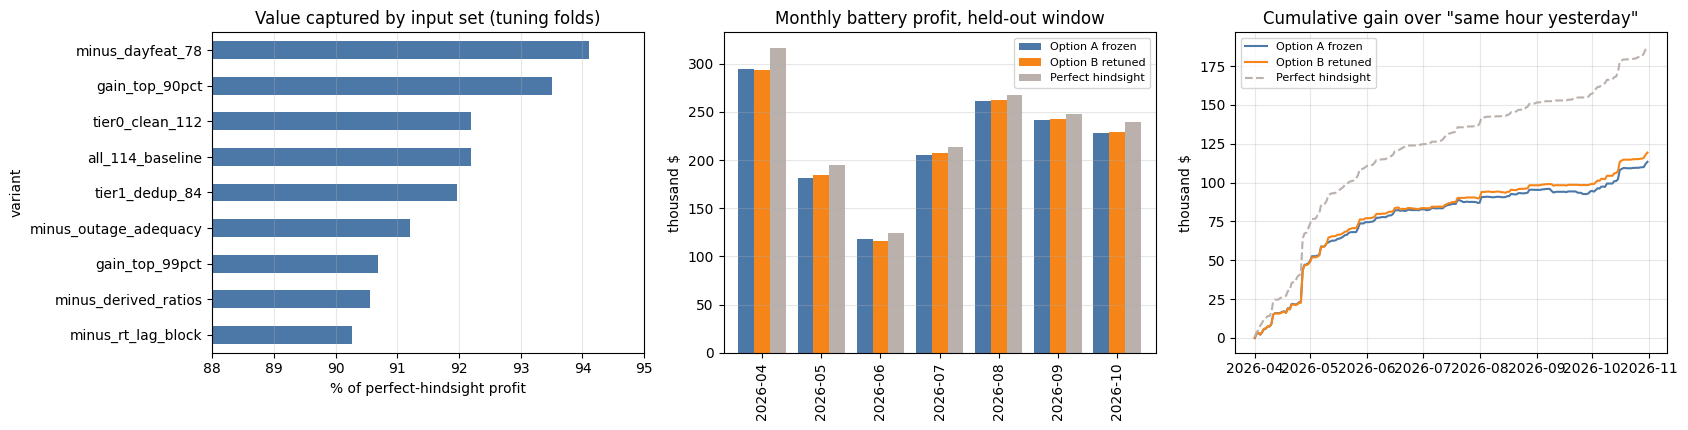

Held-out window profit: A $1531213 | B $1537158 | naive $1417873 | perfect $1605179


In [ ]:
# Battery economics: what each choice is worth in dollars to the battery owner.
_NV = bt_opt.day_profits(CMP, CMP.price_lag24.values, plan_day, day_profit, TARGET)
_moA = DP_A.assign(month=DP_A.day.str[:7])
_moB = DP_B.assign(month=DP_B.day.str[:7])
_tab = pd.DataFrame({'Option A frozen': _moA.groupby('month').profit.sum(), 'Option B retuned': _moB.groupby('month').profit.sum(), 'Perfect hindsight': _moA.groupby('month').perfect.sum()})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ABL_SUMMARY['VC_mean'].sort_values().plot.barh(ax=ax[0], color='#4C78A8')
ax[0].set_title('Value captured by input set (tuning folds)')
ax[0].set_xlabel('% of perfect-hindsight profit'); ax[0].set_xlim(88, 95); ax[0].grid(alpha=.3, axis='x')
(_tab / 1e3).plot.bar(ax=ax[1], color=['#4C78A8', '#F58518', '#BAB0AC'], width=.8)
ax[1].set_title('Monthly battery profit, held-out window')
ax[1].set_ylabel('thousand $'); ax[1].set_xlabel(''); ax[1].grid(alpha=.3, axis='y'); ax[1].legend(fontsize=8)
ax[2].plot(pd.to_datetime(DP_A.day), (DP_A.profit - _NV.profit).cumsum() / 1e3, color='#4C78A8', label='Option A frozen')
ax[2].plot(pd.to_datetime(DP_B.day), (DP_B.profit - _NV.profit).cumsum() / 1e3, color='#F58518', label='Option B retuned')
ax[2].plot(pd.to_datetime(DP_A.day), (DP_A.perfect - _NV.profit).cumsum() / 1e3, color='#BAB0AC', ls='--', label='Perfect hindsight')
ax[2].set_title('Cumulative gain over "same hour yesterday"')
ax[2].set_ylabel('thousand $'); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
print('Held-out window profit: A $%.0f | B $%.0f | naive $%.0f | perfect $%.0f' % (DP_A.profit.sum(), DP_B.profit.sum(), _NV.profit.sum(), DP_A.perfect.sum()))


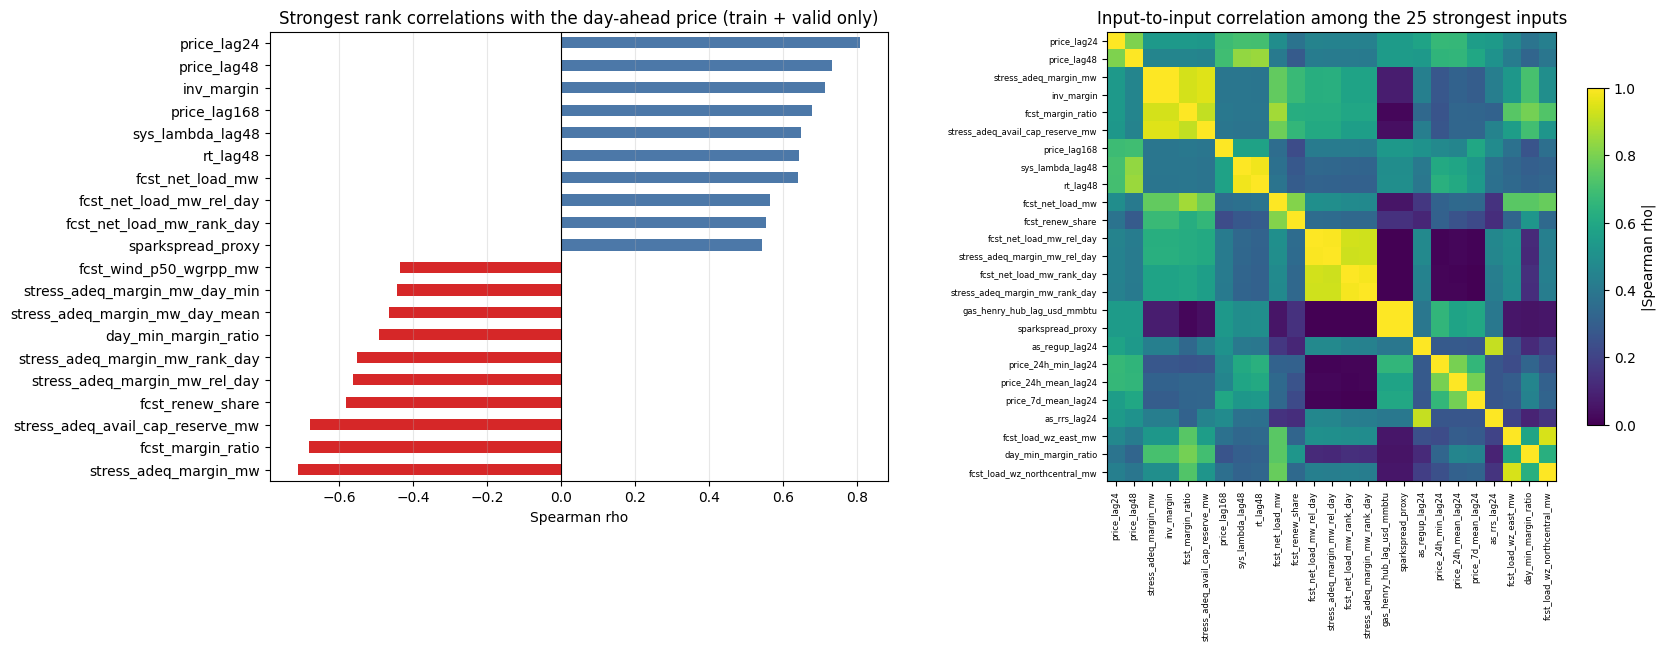

Pairs above 0.95 among these 25: 7 of 300


In [ ]:
# Price correlations. Left: how each input ranks against the day-ahead price.
# Right: how the inputs correlate with EACH OTHER - the redundancy the pruning removes.
_base = data2[_d2 < pd.Timestamp('2025-01-01')]
_R = _base[ALIVE].rank()
_sp = _R.corrwith(_base[TARGET].rank()).dropna().sort_values()
_top = pd.concat([_sp.head(10), _sp.tail(10)])
_sel = list(_sp.abs().sort_values(ascending=False).head(25).index)
_C = _R[_sel].corr().abs()
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
_top.plot.barh(ax=ax[0], color=['#D62728' if v < 0 else '#4C78A8' for v in _top.values])
ax[0].set_title('Strongest rank correlations with the day-ahead price (train + valid only)')
ax[0].set_xlabel('Spearman rho'); ax[0].axvline(0, color='black', lw=.8); ax[0].grid(alpha=.3, axis='x')
_im = ax[1].imshow(_C.values, cmap='viridis', vmin=0, vmax=1)
ax[1].set_xticks(range(len(_sel))); ax[1].set_xticklabels(_sel, rotation=90, fontsize=6)
ax[1].set_yticks(range(len(_sel))); ax[1].set_yticklabels(_sel, fontsize=6)
ax[1].set_title('Input-to-input correlation among the 25 strongest inputs')
fig.colorbar(_im, ax=ax[1], shrink=.75, label='|Spearman rho|')
plt.tight_layout(); plt.show()
print('Pairs above 0.95 among these 25:', int(((_C.values > 0.95).sum() - len(_sel)) / 2), 'of', int(len(_sel) * (len(_sel) - 1) / 2))


## 18. Findings: input set and hyperparameter optimisation

Two questions, both decided on folds that end before the test period, and both scored on money rather than price error.

### Does the model need all 114 inputs?

No. Two inputs are constant across the training window and carry nothing at all: `cal_regime_ercot_rtcb` and `fcst_solar_mw_day_min`. Of the 112 that remain, 28 are near-duplicates of another input at rho above 0.95, leaving 84 genuinely distinct signals.

The extra inputs do not merely fail to help - they cost money. Averaged over the 2023 and 2024 folds:

| Input set | Inputs | Value captured |
| --- | --- | --- |
| Original 78, no whole-day features | 78 | 94.11% |
| Gain-selected to 90% of total gain | about 19 | 93.51% |
| All 114 | 114 | 92.20% |
| Redundancy-pruned | 84 | 91.97% |
| Without the real-time lag block | 108 | 90.27% |

On the 2023 fold, which carries nearly all of the discrimination, the paired bootstrap over whole days gives:

- 78 inputs against 114: **+$457,215**, 95% CI +$55,780 to +$958,587, P(no gain) = 0.00
- 21 gain-selected inputs against 114: **+$512,195**, 95% CI -$33,479 to +$1,173,373, P(no gain) = 0.00
- 21 inputs against 78: +$54,980, 95% CI -$245,713 to +$400,093, P(no gain) = 0.40

So the 36 whole-day features added in the previous revision do not pay for themselves, and about 21 inputs do the work of 114. This closes the question the handover note left open, with a negative answer for that upgrade.

The blocks that do earn their place are the real-time lag block and the three derived ratios: removing either is the worst outcome in the table. Those are the feeds worth the vintage discipline in production.

Worth noting that MAE barely moves across every variant, 15.48 to 16.18 $/MWh, while value captured moves 3.8 points. Accuracy and money remain different things, exactly as section 11 found.

### Should the settings be retuned after RTC+B?

Option A keeps the settings chosen on 2023 and 2024, before the market redesign. Option B retunes on 2025-12-05 to 2026-04-01, the first four months of RTC+B, and spends that window in order to do so. Both are scored on 2026-04-01 onward, which neither option was allowed to see.

The two searches disagree sharply about what the model should be. A chose 127 leaves at a 0.05 learning rate; B chose 31 leaves at 0.02 - a markedly more regularised model for the new regime.

| Setting | Value captured | Profit | Rank corr | MAE |
| --- | --- | --- | --- | --- |
| A, frozen pre-RTC+B | 95.39% | $1,531,213 | 0.94 | 5.10 |
| B, retuned on RTC+B | 95.76% | $1,537,158 | 0.94 | 5.12 |
| Same hour yesterday | 88.33% | $1,417,873 | 0.82 | 8.53 |

Paired bootstrap, B minus A: **+$5,945**, 95% CI -$1,571 to +$14,906, P(no gain) = 0.065.

**Option A is the better choice on this evidence.** Retuning buys 0.37 points of value captured, about 0.4% of profit, it is not significant at the 5% level, and it costs four months of test period to obtain. The honest position is to keep the settings frozen and state the limitation - the only post-redesign data available sits inside the test window - rather than spend test data chasing a gain this small.
